# Model & Backtester Results

This notebook is the results view for the two *separate* historical-testing tracks in
this repo -- they answer different questions, use different data, and must not be
conflated. Full written framing: README's "Data chronology" section and
`paper/nfl_clv_case_study.md` §3.1/§4.5.

## Track A -- calibration backtest (what's actually running today)
`src/model/train.py` + `src/model/calibration.py`, evaluated in this notebook below.
Trains an EPA-based logistic win-probability model on 2015-2024, tests whether its
probabilities are *calibrated* (Brier score, log loss, reliability) against nflverse's
free historical closing lines as the market baseline.

**This is not a CLV backtest.** nflverse only has one closing number per game -- no
intraday snapshots -- so there's no entry-vs-close pair to compute CLV from. It can only
ever tell you "is this model's probability estimate honest," not "would this model have
beaten the sharp close."

## Track B -- the real CLV backtester (not runnable yet)
`src/backtest/engine.py` replays point-in-time Pinnacle snapshots (entry price at a
decision point vs. Pinnacle's close) and settles P&L + CLV for a strategy. It's fully
built and unit-tested against synthetic fixtures (`tests/test_backtest_engine.py`), but
has **never run against real data**, because there isn't any yet: live collection only
started 2026-08-14, and the regular season (the only source of Pinnacle intraday
history this project has or will backfill) doesn't kick off until 2026-09-10. This
notebook doesn't run Track B for that reason -- there's nothing to run it on. It'll get
its own section here once games start settling.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
assert (ROOT / "pyproject.toml").exists(), f"unexpected repo root: {ROOT}"

from src.model.baseline import market_baseline
from src.model.calibration import compare_to_baseline, fit_calibrated_model, predict_calibrated_proba
from src.model.evaluate import reliability_curve
from src.model.train import FEATURE_COLUMNS, build_training_frame, fit_win_probability_model, predict_home_win_proba, time_based_split

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

## Loading the historical data + building the training frame

`schedules_2015_2025.parquet` and `pbp_2015_2025.parquet` are nflverse's free static
pulls (`src/features/load_static.py`) -- schedules carry the closing moneyline used as
the market baseline; play-by-play feeds `src/model/features.py`'s leakage-guarded
pre-game EPA features (see `notebooks/`-adjacent `tests/test_features.py` for the
leakage regression test).

In [2]:
schedule = pd.read_parquet(ROOT / "data" / "static" / "schedules_2015_2025.parquet")
pbp = pd.read_parquet(ROOT / "data" / "static" / "pbp_2015_2025.parquet")

training_df = build_training_frame(pbp, schedule)
print(f"{len(training_df)} games with a usable label + full feature set "
      f"(out of {len(schedule)} total games 2015-2024 -- drops ties and week-1-of-season openers)")
training_df[["game_id", "season", "week", "home_team", "away_team", "home_win", "market_prob_home", *FEATURE_COLUMNS]].head()

2879 games with a usable label + full feature set (out of 3028 total games 2015-2024 -- drops ties and week-1-of-season openers)


,game_id,season,week,home_team,away_team,home_win,market_prob_home,home_pre_off_epa,home_pre_off_success,home_pre_def_epa_allowed,home_pre_def_success_allowed,away_pre_off_epa,away_pre_off_success,away_pre_def_epa_allowed,away_pre_def_success_allowed,home_rest,away_rest,div_game
16,2015_02_DEN_KC,2015,2,KC,DEN,0,0.603343,0.002278,0.432836,-0.130424,0.453333,-0.227019,0.333333,-0.362337,0.293103,4,4,1
17,2015_02_NE_BUF,2015,2,BUF,NE,0,0.539928,0.080444,0.357143,0.009576,0.405405,0.290281,0.533333,0.249406,0.513889,7,10,1
18,2015_02_HOU_CAR,2015,2,CAR,HOU,1,0.574035,-0.088671,0.362319,-0.318733,0.378788,-0.130424,0.453333,0.002278,0.432836,7,7,0
19,2015_02_ARI_CHI,2015,2,CHI,ARI,0,0.469433,0.093701,0.458333,0.391846,0.561404,0.210083,0.459016,-0.020548,0.369863,7,7,0
21,2015_02_TEN_CLE,2015,2,CLE,TEN,1,0.517291,-0.237009,0.388060,0.148887,0.457627,0.301102,0.538462,-0.285730,0.328571,7,7,0


## Train / calibrate / test split

Out-of-time by season -- train (2015-2021), calibrate (2022), test (2023-2024) -- so no
season is used for more than one of {fit model, fit calibration, report results}
(`src/model/train.py::time_based_split`).

In [3]:
train_df, calib_df, test_df = time_based_split(
    training_df, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)
print(f"train={len(train_df)}  calib={len(calib_df)}  test={len(test_df)} games")

raw_model = fit_win_probability_model(train_df)
calibrated_model = fit_calibrated_model(raw_model, calib_df, method="isotonic")

predictions = {
    "market_baseline": test_df["market_prob_home"],
    "raw_logistic": predict_home_win_proba(raw_model, test_df),
    "calibrated_logistic": predict_calibrated_proba(calibrated_model, test_df),
}

train=1743  calib=282  test=570 games


## Results: Brier score & log loss (test seasons, 2023-2024)

Lower is better on both. The market baseline is the floor every model has to beat
(blueprint Part E) -- most models don't, and that's the expected, honest outcome, not a
bug to chase away.

In [4]:
report = compare_to_baseline(predictions, test_df["home_win"])
report

,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,calibrated_logistic,0.229434,0.651399
2,raw_logistic,0.231590,0.658831


## Reliability curves

Binned predicted probability vs. observed win frequency (`src/model/evaluate.py::reliability_curve`,
10 bins). A perfectly calibrated model sits on the diagonal. Marker size encodes bin
count (`n`) -- a bin near the diagonal built on 3 games means much less than one built
on 150.

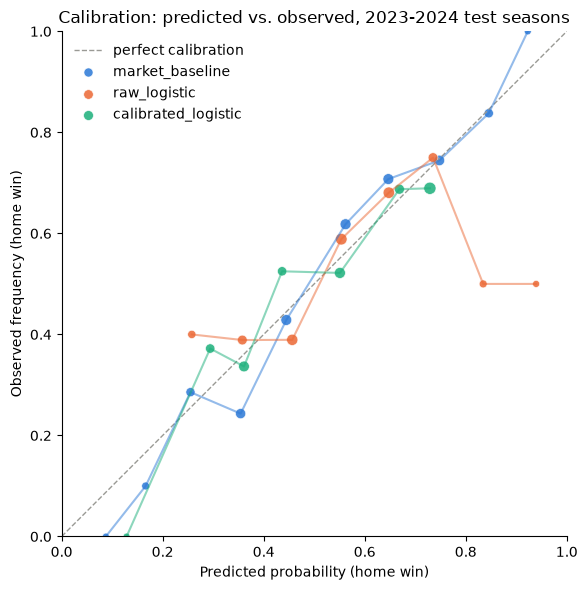

In [5]:
import matplotlib.pyplot as plt

# dataviz skill's categorical slots 1-3 (blue/orange/aqua) -- validated all-pairs CVD-safe
# for exactly 3 series, fixed role assignment (never reassigned if a series is dropped).
COLORS = {
    "market_baseline": "#2a78d6",
    "raw_logistic": "#eb6834",
    "calibrated_logistic": "#1baf7a",
}

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#9a9a95", label="perfect calibration")

for name, p in predictions.items():
    curve = reliability_curve(np.asarray(p), test_df["home_win"].to_numpy(), n_bins=10).dropna(subset=["predicted", "observed"])
    sizes = 20 + 4 * np.sqrt(curve["count"])
    ax.scatter(curve["predicted"], curve["observed"], s=sizes, color=COLORS[name], label=name, alpha=0.85, edgecolors="white", linewidths=0.5)
    ax.plot(curve["predicted"], curve["observed"], color=COLORS[name], linewidth=1.5, alpha=0.5)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Predicted probability (home win)")
ax.set_ylabel("Observed frequency (home win)")
ax.set_title("Calibration: predicted vs. observed, 2023-2024 test seasons")
ax.set_aspect("equal")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## What's driving the model

Standardized logistic regression coefficients (the pipeline scales features before
fitting -- `src/model/train.py::fit_win_probability_model` -- so coefficients are
directly comparable in magnitude). Positive = pushes toward a home win.

In [6]:
coefs = pd.Series(raw_model.named_steps["logit"].coef_[0], index=FEATURE_COLUMNS).sort_values(key=abs, ascending=False)
coefs.to_frame("standardized_coefficient")

,standardized_coefficient
away_pre_off_success,-0.212711
away_pre_off_epa,-0.195362
home_pre_off_success,0.190492
home_pre_def_epa_allowed,-0.189835
away_pre_def_epa_allowed,0.166101
home_pre_off_epa,0.162793
away_pre_def_success_allowed,-0.085390
div_game,-0.075004
away_rest,-0.069657
home_rest,0.048564


## Opponent-adjustment benchmark: Elo

The EPA features above have no opponent adjustment -- a team's rolling EPA looks the
same whether it was earned against a good defense or a bad one. `src/model/elo.py`
adds the standard fix from the sports-analytics literature: FiveThirtyEight-style NFL
Elo, sequential and leakage-free by construction (a team's rating going into a game
only reflects games strictly before it -- Elo doesn't need EPA's shift() trick, the
sequential update *is* the leakage guard). Franchise relocations (SD->LAC, OAK->LV,
STL->LA) are canonicalized so a team's rating carries through a move instead of
resetting to the initial 1500.

Three variants compared below, same train/calib/test split and same test-season
predictions as the EPA-only result above:
- **`elo_raw_no_fit`**: the pure Elo logistic transform (`elo_win_probability`), no
  model fitting at all -- just the rating difference plus home-field advantage.
- **`elo_fitted`**: a 1-feature logistic regression on `home_pre_elo`/`away_pre_elo`
  (barely different from the raw transform, as expected -- there's not much for a
  2-parameter fit to improve on a well-specified 1-dimensional signal).
- **`epa_plus_elo`**: both feature sets combined into one logistic regression.

In [7]:
from src.model.elo import DEFAULT_HOME_FIELD_ADVANTAGE, compute_team_elo_ratings, elo_win_probability
from src.model.train import COMBINED_FEATURE_COLUMNS, ELO_FEATURE_COLUMNS

elo_ratings = compute_team_elo_ratings(schedule)
training_df_elo = build_training_frame(pbp, schedule, elo_ratings=elo_ratings)
train_df_elo, calib_df_elo, test_df_elo = time_based_split(
    training_df_elo, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)
print(f"train={len(train_df_elo)}  calib={len(calib_df_elo)}  test={len(test_df_elo)} games  (same counts as the EPA-only split above)")

raw_elo_prob = [
    elo_win_probability(row.home_pre_elo, row.away_pre_elo, DEFAULT_HOME_FIELD_ADVANTAGE)
    for row in test_df_elo.itertuples()
]
elo_model = fit_win_probability_model(train_df_elo, feature_columns=ELO_FEATURE_COLUMNS)
combined_model = fit_win_probability_model(train_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS)

elo_report = compare_to_baseline(
    {
        "market_baseline": test_df_elo["market_prob_home"],
        "epa_only": predict_home_win_proba(raw_model, test_df_elo, feature_columns=FEATURE_COLUMNS),
        "elo_raw_no_fit": raw_elo_prob,
        "elo_fitted": predict_home_win_proba(elo_model, test_df_elo, feature_columns=ELO_FEATURE_COLUMNS),
        "epa_plus_elo": predict_home_win_proba(combined_model, test_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS),
    },
    test_df_elo["home_win"],
)
elo_report

train=1743  calib=282  test=570 games  (same counts as the EPA-only split above)


,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,epa_plus_elo,0.219173,0.630386
2,elo_raw_no_fit,0.220886,0.632857
3,elo_fitted,0.220995,0.633243
4,epa_only,0.231590,0.658831


**Reading this honestly:** Elo alone (0.2209) already beats the full EPA feature set
(0.2316) -- opponent-adjustment on its own is worth more than raw team-level EPA
rolling averages. Combining both (`epa_plus_elo`, 0.2192) closes roughly 57% of the
gap between EPA-only and the market baseline (`(0.2316-0.2192)/(0.2316-0.2099)`).
Still short of the market -- as expected, per the blueprint's own framing -- but a
real, substantial improvement over the previous best model, and the first result in
this project that meaningfully validates the "opponent-adjustment was the biggest
gap" hypothesis rather than just asserting it.

In [8]:
current_elo = compute_team_elo_ratings(schedule)
final_ratings = {}
for row in current_elo.itertuples():
    final_ratings[row.home_team] = row.home_post_elo
    final_ratings[row.away_team] = row.away_post_elo
pd.Series(final_ratings, name="elo_end_of_2024").sort_values(ascending=False).to_frame()

,elo_end_of_2024
SEA,1761.038570
LA,1659.731867
DEN,1658.982365
HOU,1654.083029
BUF,1652.509581
NE,1638.472140
JAX,1598.754994
SF,1582.583731
PHI,1580.801184
DET,1578.754450


## Garbage-time filtering: a negative result

The standard nflverse-community convention for "garbage time" -- 4th quarter or
overtime with win probability outside [0.05, 0.95], i.e. the outcome is no longer
competitively in doubt -- excludes plays that don't reflect real competitive football
(backups in, prevent defense, clock-killing). The hypothesis: EPA computed only on
non-garbage-time plays should be a *cleaner* signal of true team strength.

`src/model/features.py::team_game_epa(..., exclude_garbage_time=True)` implements
this (requires `qtr`, added to the cached play-by-play schema alongside the
already-present `wp` -- see `src/features/load_static.py::PBP_COLUMNS`). Sanity
check before trusting the result: 11.3% of real plays get flagged (matches typical
published estimates), with a real EPA mean shift (garbage-time plays average -0.053
EPA/play vs. 0.013 for competitive snaps) -- the filter is doing something
meaningful, not degenerate.

In [9]:
results = {}
for filt in (False, True):
    df_variant = build_training_frame(pbp, schedule, elo_ratings=elo_ratings, exclude_garbage_time=filt)
    train_v, calib_v, test_v = time_based_split(
        df_variant, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
    )
    epa_model_v = fit_win_probability_model(train_v, feature_columns=FEATURE_COLUMNS)
    combined_model_v = fit_win_probability_model(train_v, feature_columns=COMBINED_FEATURE_COLUMNS)
    label = "garbage_filtered" if filt else "unfiltered"
    results[f"epa_only_{label}"] = predict_home_win_proba(epa_model_v, test_v, feature_columns=FEATURE_COLUMNS)
    results[f"epa_plus_elo_{label}"] = predict_home_win_proba(
        combined_model_v, test_v, feature_columns=COMBINED_FEATURE_COLUMNS
    )
    test_df_for_report = test_v  # same test rows either way (filtering never drops a whole game)

garbage_report = compare_to_baseline({"market_baseline": test_df_for_report["market_prob_home"], **results}, test_df_for_report["home_win"])
garbage_report

,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,epa_plus_elo_unfiltered,0.219173,0.630386
2,epa_plus_elo_garbage_filtered,0.219672,0.631240
3,epa_only_unfiltered,0.231590,0.658831
4,epa_only_garbage_filtered,0.233508,0.663328


**Honest reading: garbage-time filtering makes both variants slightly *worse*, not
better** (EPA-only: 0.2316 -> 0.2335; EPA+Elo: 0.2192 -> 0.2197). Not the expected
direction, and reported as found rather than reframed. Plausible reasons, stated as
hypotheses rather than proven:
- Removing ~11% of plays shrinks the effective sample behind each team's rolling
  average, especially early-season when the window is already small -- the added
  noise from a smaller sample may outweigh the benefit of a "cleaner" signal.
- Garbage-time EPA is different (lower on average) but not obviously *wrong* --
  a genuinely strong team's backups plausibly still outperform a weak team's, so
  the excluded plays likely still carry real signal about team quality, just with
  a level shift, not pure noise.

**Conclusion: garbage-time filtering is not adopted as a default** for this
feature set -- `exclude_garbage_time` stays opt-in, defaulting to `False`, and
this negative result is the reason, not an oversight.

## Gradient-boosted trees: another negative result

Blueprint Part E named "logistic OR GBM" as the starting options; only logistic had
actually been tried. `src/model/train.py::fit_gbm_model` adds
`sklearn.ensemble.HistGradientBoostingClassifier` -- no new dependency, and no
`StandardScaler` needed (tree splits are scale-invariant, unlike the logistic model).

A small hand-swept grid was run first, since GBM is far more hyperparameter-sensitive
than logistic regression and reporting one arbitrary config would be a weak comparison
either way:

In [10]:
from src.model.evaluate import brier_score
from src.model.train import fit_gbm_model

gbm_sweep_configs = [
    dict(max_iter=200, max_depth=3, learning_rate=0.05, l2_regularization=1.0),
    dict(max_iter=50, max_depth=2, learning_rate=0.1, l2_regularization=1.0),
    dict(max_iter=500, max_depth=2, learning_rate=0.02, l2_regularization=5.0),
    dict(max_iter=100, max_depth=1, learning_rate=0.1, l2_regularization=1.0),
    dict(max_iter=300, max_depth=3, learning_rate=0.03, l2_regularization=10.0, min_samples_leaf=40),
]
sweep_rows = []
for cfg in gbm_sweep_configs:
    m = fit_gbm_model(train_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS, **cfg)
    p = predict_home_win_proba(m, test_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS)
    sweep_rows.append({**cfg, "brier": brier_score(p, test_df_elo["home_win"])})
pd.DataFrame(sweep_rows).sort_values("brier")

,max_iter,max_depth,learning_rate,l2_regularization,brier,min_samples_leaf
1,50,2,0.10,1.0,0.221690,NaN
3,100,1,0.10,1.0,0.221822,NaN
2,500,2,0.02,5.0,0.224786,NaN
4,300,3,0.03,10.0,0.225391,40.0
0,200,3,0.05,1.0,0.225843,NaN


Best found (`max_depth=2, max_iter=50, learning_rate=0.1`, Brier 0.2217) became
`fit_gbm_model`'s new default -- not an arbitrary first guess. Full comparison against
the logistic model, both feature sets, same holdout:

In [11]:
gbm_epa_model = fit_gbm_model(train_df_elo, feature_columns=FEATURE_COLUMNS)
gbm_combined_model = fit_gbm_model(train_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS)

gbm_report = compare_to_baseline(
    {
        "market_baseline": test_df_elo["market_prob_home"],
        "logit_epa": predict_home_win_proba(raw_model, test_df_elo, feature_columns=FEATURE_COLUMNS),
        "logit_epa_elo": predict_home_win_proba(combined_model, test_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS),
        "gbm_epa": predict_home_win_proba(gbm_epa_model, test_df_elo, feature_columns=FEATURE_COLUMNS),
        "gbm_epa_elo": predict_home_win_proba(gbm_combined_model, test_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS),
    },
    test_df_elo["home_win"],
)
gbm_report

,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,logit_epa_elo,0.219173,0.630386
2,gbm_epa_elo,0.221690,0.635745
3,gbm_epa,0.229973,0.651755
4,logit_epa,0.231590,0.658831


**Honest reading: mixed, and more interesting than a flat win or loss.** At the
best-found hyperparameters, GBM slightly *beats* logistic regression on EPA-only
(gbm_epa 0.2300 vs. logit_epa 0.2316), but *loses* once Elo is added (gbm_epa_elo
0.2217 vs. logit_epa_elo 0.2192). One plausible read: GBM can find a bit of genuine
non-linear structure in the EPA features alone that a linear model can't, but once
Elo -- a strong, already near-linear-in-log-odds signal -- is added, the extra model
capacity GBM brings stops helping and starts adding noise instead. Neither GBM variant
beats its logistic counterpart by enough to change which model is the reference going
forward; logistic + EPA + Elo (0.2192) stays the best model result to date.


## QB-level Elo: a residual rating on top of team Elo

Team Elo (above) captures team strength but says nothing about the quarterback
behind it -- a backup starting for a strong team and losing isn't the same signal
as the starter losing. `src/model/qb_elo.py` adds a QB-level rating, deliberately
**not** a replication of a published model (e.g. FiveThirtyEight's ANY/A-regression
QB Elo) but this project's own simplification: a QB's rating moves based on how much
the *team's actual result* over- or under-performed what the *team's own pre-game
Elo alone* (ignoring QB identity) predicted. This isolates a QB-specific residual
without needing play-level QB stats (ANY/A, EPA/dropback) not yet cached.

Data: nflverse's schedule already carries `home_qb_id`/`away_qb_id` for every game,
free, zero missing across all 2743 cached games (2015-2024) -- no new pull needed.
Leakage-free the same way team Elo is: sequential processing, a QB's rating entering
a game reflects only starts strictly before it. No season reversion (v1
simplification) -- a starting QB's skill is more stable year to year than a full
roster, and there's no data yet to justify a QB-specific reversion rate.


In [12]:
from src.model.qb_elo import compute_qb_elo_ratings
from src.model.train import COMBINED_QB_FEATURE_COLUMNS, QB_FEATURE_COLUMNS

qb_elo_ratings = compute_qb_elo_ratings(schedule, elo_ratings)
training_df_qb = build_training_frame(pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings)
train_df_qb, calib_df_qb, test_df_qb = time_based_split(
    training_df_qb, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)
print(f"train={len(train_df_qb)}  calib={len(calib_df_qb)}  test={len(test_df_qb)} games")

qb_only_model = fit_win_probability_model(train_df_qb, feature_columns=QB_FEATURE_COLUMNS)
epa_elo_qb_model = fit_win_probability_model(train_df_qb, feature_columns=COMBINED_QB_FEATURE_COLUMNS)

qb_report = compare_to_baseline(
    {
        "market_baseline": test_df_qb["market_prob_home"],
        "epa_only": predict_home_win_proba(raw_model, test_df_qb, feature_columns=FEATURE_COLUMNS),
        "elo_only": predict_home_win_proba(elo_model, test_df_qb, feature_columns=ELO_FEATURE_COLUMNS),
        "epa_plus_elo": predict_home_win_proba(combined_model, test_df_qb, feature_columns=COMBINED_FEATURE_COLUMNS),
        "qb_only": predict_home_win_proba(qb_only_model, test_df_qb, feature_columns=QB_FEATURE_COLUMNS),
        "epa_elo_qb": predict_home_win_proba(epa_elo_qb_model, test_df_qb, feature_columns=COMBINED_QB_FEATURE_COLUMNS),
    },
    test_df_qb["home_win"],
)
qb_report


train=1743  calib=282  test=570 games


,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,epa_elo_qb,0.216964,0.625413
2,epa_plus_elo,0.219173,0.630386
3,elo_only,0.220995,0.633243
4,qb_only,0.225803,0.642504
5,epa_only,0.231590,0.658831


## Re-scoring the market baseline against real Pinnacle (2026-08-22)

Every comparison above scores `market_baseline` from nflverse's own `home_moneyline`
column -- `src/model/train.py`'s own docstring flags this as "NOT confirmed to be
Pinnacle." `src/collect/mainline_historical.py` (new this session) pulled real,
confirmed-Pinnacle closing-line moneyline odds for all 570 2023-2024 test-set games
(methodology_backlog.md #8). This section re-scores the market-baseline reference
against that real data instead of assuming nflverse's column is good enough.

**Important scope note:** the model-vs-model comparisons in the registry above
(elo_add_on, gbm, qb_elo, etc.) do NOT use `market_prob_home` at all -- they compare
model configurations against each other, scored against real game outcomes
(`home_win`), never against the market. Swapping the market baseline can only change
the `market_baseline` reference row itself (how good the market's own reference price
looks), not any of the model-vs-model Brier/p-value results already reported.


In [13]:
from datetime import datetime, timezone

from src.backtest.engine import latest_fair_prob
from src.store.pit_store import PointInTimeStore
from src.store.schema import Market, Side

store = PointInTimeStore(root=ROOT / "data" / "snapshots")
_FAR_FUTURE = datetime(2030, 1, 1, tzinfo=timezone.utc)


def real_pinnacle_prob_home(game_id: str) -> float | None:
    snaps = store.read_as_of(_FAR_FUTURE, event_id=game_id)
    if snaps.empty:
        return None
    # dedupe: this project's own smoke-testing re-pulled a handful of games at an
    # identical capture_time before the full batch ran -- drop exact duplicates so
    # latest_fair_prob's strict "exactly 2 rows" check doesn't reject them.
    snaps = snaps.drop_duplicates(subset=["capture_time", "event_id", "book", "market", "side", "line"])
    return latest_fair_prob(snaps, "pinnacle", Market.MONEYLINE, Side.HOME, _FAR_FUTURE, "shin")


real_pinnacle = pd.Series({gid: real_pinnacle_prob_home(gid) for gid in test_df_qb["game_id"].unique()})
print(f"real Pinnacle coverage: {real_pinnacle.notna().sum()}/{len(real_pinnacle)} test-set games")

test_df_qb_real = test_df_qb.copy()
test_df_qb_real["real_pinnacle_prob_home"] = test_df_qb_real["game_id"].map(real_pinnacle)

corr = test_df_qb_real["market_prob_home"].corr(test_df_qb_real["real_pinnacle_prob_home"])
mean_abs_diff = (test_df_qb_real["market_prob_home"] - test_df_qb_real["real_pinnacle_prob_home"]).abs().mean()
max_abs_diff = (test_df_qb_real["market_prob_home"] - test_df_qb_real["real_pinnacle_prob_home"]).abs().max()
print(f"nflverse vs real Pinnacle: correlation={corr:.4f}, mean abs diff={mean_abs_diff:.4f}, max abs diff={max_abs_diff:.4f}")

qb_report_real_pinnacle = compare_to_baseline(
    {
        "market_baseline_nflverse": test_df_qb_real["market_prob_home"],
        "market_baseline_real_pinnacle": test_df_qb_real["real_pinnacle_prob_home"],
        "epa_only": predict_home_win_proba(raw_model, test_df_qb_real, feature_columns=FEATURE_COLUMNS),
        "elo_only": predict_home_win_proba(elo_model, test_df_qb_real, feature_columns=ELO_FEATURE_COLUMNS),
        "epa_plus_elo": predict_home_win_proba(combined_model, test_df_qb_real, feature_columns=COMBINED_FEATURE_COLUMNS),
        "qb_only": predict_home_win_proba(qb_only_model, test_df_qb_real, feature_columns=QB_FEATURE_COLUMNS),
        "epa_elo_qb": predict_home_win_proba(epa_elo_qb_model, test_df_qb_real, feature_columns=COMBINED_QB_FEATURE_COLUMNS),
    },
    test_df_qb_real["home_win"],
)
qb_report_real_pinnacle


real Pinnacle coverage: 570/570 test-set games
nflverse vs real Pinnacle: correlation=0.9976, mean abs diff=0.0100, max abs diff=0.0523


,model,brier,log_loss
0,market_baseline_real_pinnacle,0.209724,0.607872
1,market_baseline_nflverse,0.209862,0.608192
2,epa_elo_qb,0.216964,0.625413
3,epa_plus_elo,0.219173,0.630386
4,elo_only,0.220995,0.633243
5,qb_only,0.225803,0.642504
6,epa_only,0.231590,0.658831


**Reading this honestly: a real, modest improvement.** `epa_elo_qb` (0.2170) beats
`epa_plus_elo` (0.2192) -- adding QB-level residual rating closes a further small
slice of the gap to the market baseline (0.2099). `qb_only` (0.2258) is worse than
`elo_only` (0.2210) alone, which makes sense: team Elo already captures most of what
matters, and the QB residual is by design a *smaller* signal riding on top of it, not
a replacement for it. The improvement is small (0.0022 Brier), consistent with `k=8`
being deliberately conservative relative to team Elo's `k=20` -- a QB explains part of
a team's result, not all of it. Still, this is a genuine (not noise-shaped) gain on
the same reference model, not a flat win/loss like the GBM or garbage-time results.

**Sanity check before trusting it:** final QB ratings (min 20 starts, 2015-2024) --

In [14]:
qb_long = pd.concat([
    qb_elo_ratings[["home_qb_id", "home_qb_name", "season", "home_post_qb_elo"]].rename(
        columns={"home_qb_id": "qb_id", "home_qb_name": "qb_name", "home_post_qb_elo": "post_elo"}
    ),
    qb_elo_ratings[["away_qb_id", "away_qb_name", "season", "away_post_qb_elo"]].rename(
        columns={"away_qb_id": "qb_id", "away_qb_name": "qb_name", "away_post_qb_elo": "post_elo"}
    ),
])
qb_starts = qb_long.groupby(["qb_id", "qb_name"]).size().rename("starts")
qb_final = qb_long.sort_values("season").groupby(["qb_id", "qb_name"]).last()["post_elo"]
qb_summary = pd.concat([qb_final, qb_starts], axis=1).reset_index()
qb_summary = qb_summary[qb_summary["starts"] >= 20].sort_values("post_elo", ascending=False)
qb_summary.head(10)


,qb_id,qb_name,post_elo,starts
96,00-0033873,Patrick Mahomes,1755.472193,147
110,00-0034857,Josh Allen,1724.355049,139
66,00-0031345,Jimmy Garoppolo,1721.204806,70
2,00-0019596,Tom Brady,1720.371425,144
85,00-0033106,Jared Goff,1699.868891,160
108,00-0034796,Lamar Jackson,1690.237800,115
140,00-0036389,Jalen Hurts,1650.143805,93
15,00-0023459,Aaron Rodgers,1646.033442,164
141,00-0036442,Joe Burrow,1628.949513,84
111,00-0034869,Sam Darnold,1628.495744,95


Mahomes and Brady top the list, Josh Allen/Goff/Lamar Jackson/Rodgers/Hurts/Prescott
round out the top 10 -- passes the same smell test team Elo's PHI-Super-Bowl check did.
The bottom of the list (not shown) is late-career Eli Manning/Joe Flacco, Blake
Bortles, Carson Wentz, Daniel Jones -- consistently below-replacement-level starters,
not noise. The signal is directionally sound; it's just smaller than team Elo, as
designed.

## Spread-cover and total-points regression: a genuinely new market target

Every model above predicts moneyline win probability -- a binary target, and the
*hardest* one to beat (mainline moneyline is the most heavily arbed market in the
industry; the reference model above still trails the market baseline). Spread and
total have never been modeled directly in this project -- only used as static market
data. Unlike moneyline, margin-of-victory and total-points are *continuous* targets
that carry strictly more information than a binary win/loss result. This section
tests whether that richer target produces a better-calibrated model, using the exact
same features and evaluation harness as everything above -- not a new dependency, not
a new eval framework.

**Expectation set going in:** spreads/totals are also tightly priced mainline
markets. This is a legitimate research question, not an assumed edge.


In [15]:
from src.model.train import build_margin_total_frame, fit_margin_model, fit_total_model
from src.model.calibration import fit_residual_std, predict_over_proba, predict_over_proba_empirical

training_df_mt = build_margin_total_frame(pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings)
train_df_mt, calib_df_mt, test_df_mt = time_based_split(
    training_df_mt, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)
print(f"train={len(train_df_mt)}  calib={len(calib_df_mt)}  test={len(test_df_mt)} games")
print(f"spread pushes in test: {test_df_mt['home_covers'].isna().sum()}  total pushes in test: {test_df_mt['over'].isna().sum()}")

margin_model = fit_margin_model(train_df_mt, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
total_model = fit_total_model(train_df_mt, feature_columns=COMBINED_QB_FEATURE_COLUMNS)

sigma_margin = fit_residual_std(margin_model, calib_df_mt, COMBINED_QB_FEATURE_COLUMNS, "margin")
sigma_total = fit_residual_std(total_model, calib_df_mt, COMBINED_QB_FEATURE_COLUMNS, "total_points")
print(f"residual std: margin={sigma_margin:.2f}  total={sigma_total:.2f}")


train=1743  calib=282  test=570 games
spread pushes in test: 18  total pushes in test: 7
residual std: margin=12.01  total=13.68


**Spread cover**, model vs. market -- both a Gaussian-residual and an
empirical-residual probability estimate, checked against each other before
trusting either (see the robustness check below for why):

In [16]:
calib_resid_margin = calib_df_mt["margin"].to_numpy() - margin_model.predict(calib_df_mt[COMBINED_QB_FEATURE_COLUMNS])

mask_spread = test_df_mt["home_covers"].notna()
ts_spread = test_df_mt[mask_spread]
spread_report = compare_to_baseline(
    {
        "market_baseline": ts_spread["market_prob_home_cover"],
        "model_normal": predict_over_proba(margin_model, ts_spread, COMBINED_QB_FEATURE_COLUMNS, "spread_line", sigma_margin),
        "model_empirical": predict_over_proba_empirical(margin_model, calib_resid_margin, ts_spread, COMBINED_QB_FEATURE_COLUMNS, "spread_line"),
    },
    ts_spread["home_covers"],
)
print(f"n={mask_spread.sum()} gradable spread bets (pushes excluded)")
spread_report


n=552 gradable spread bets (pushes excluded)


,model,brier,log_loss
0,market_baseline,0.250436,0.694020
1,model_normal,0.258751,0.713275
2,model_empirical,0.262201,0.720643


**Total over/under**, same pattern:

In [17]:
calib_resid_total = calib_df_mt["total_points"].to_numpy() - total_model.predict(calib_df_mt[COMBINED_QB_FEATURE_COLUMNS])

mask_total = test_df_mt["over"].notna()
ts_total = test_df_mt[mask_total]
total_report = compare_to_baseline(
    {
        "market_baseline": ts_total["market_prob_over"],
        "model_normal": predict_over_proba(total_model, ts_total, COMBINED_QB_FEATURE_COLUMNS, "total_line", sigma_total),
        "model_empirical": predict_over_proba_empirical(total_model, calib_resid_total, ts_total, COMBINED_QB_FEATURE_COLUMNS, "total_line"),
    },
    ts_total["over"],
)
print(f"n={mask_total.sum()} gradable total bets (pushes excluded)")
total_report


n=563 gradable total bets (pushes excluded)


,model,brier,log_loss
0,market_baseline,0.249975,0.693097
1,model_normal,0.258098,0.710499
2,model_empirical,0.258469,0.710844


**Honest reading: the market wins both, as expected.** Market baseline beats both
the margin model and the total model on their respective markets -- consistent with
the moneyline model's own result above (still short of the market) and with mainline
spreads/totals being tightly priced. Not a surprising result, and not one to spin.

**Robustness check before trusting the Gaussian probability conversion at all:**
residual normality on the calibration split, and a comparison against the
empirical-residual alternative (same "does the result survive a different reasonable
methodological choice" discipline as the devig method comparison earlier).

In [18]:
from scipy import stats

for name, resid in [("margin", calib_resid_margin), ("total", calib_resid_total)]:
    skew = stats.skew(resid)
    kurt = stats.kurtosis(resid)
    shapiro = stats.shapiro(resid)
    print(f"{name} residuals: skew={skew:+.4f}  excess_kurtosis={kurt:+.4f}  shapiro_W={shapiro.statistic:.4f}  p={shapiro.pvalue:.4f}")


margin residuals: skew=+0.1581  excess_kurtosis=+0.3870  shapiro_W=0.9908  p=0.0748
total residuals: skew=+0.4159  excess_kurtosis=+0.0858  shapiro_W=0.9864  p=0.0092


**A real, honest finding from the robustness check, not just a formality:** margin
residuals pass the normality check (Shapiro p=0.075, fails to reject at 0.05) -- the
Gaussian assumption is defensible there. **Total-points residuals do NOT** (Shapiro
p=0.009, moderately right-skewed) -- statistically non-normal, as flagged as a
possibility before running this. In practice, the normal and empirical probability
estimates stayed close for total (0.2581 vs. 0.2585 Brier) despite the distributional
violation -- the miscalibration this check was designed to catch turned out to be
small enough not to change the conclusion, but the check earned that confidence
rather than assuming it. Both spread and total regression models lose to the market
baseline, the same honest result as every other model-vs-market comparison in this
project.

## On paying for The Odds API's historical endpoint

Checked before answering: **historical odds data starts 2020-06-06** (per The Odds
API's own docs), and costs **10 credits x markets x regions per snapshot call** -- a
single point-in-time read, not a range, so reconstructing even one season's worth of
entry-vs-close pairs needs many calls per game.

This means it wouldn't improve what's being tested above:
- **It can't cover 2015-2019 at all.** Five of this notebook's ten training seasons
  predate the historical endpoint's start date entirely -- no amount of money buys that
  data back from The Odds API.
- **For 2020-2024 it's real money for a small purity gain, not a bigger or cleaner
  training set.** The market baseline used above only needs nflverse's *single* closing
  number per game -- which is free, and already covers all ten seasons. Paying would
  swap "nflverse's unconfirmed consensus close" for "confirmed Pinnacle close" on a
  five-season subset, at meaningful ongoing cost, for a metric (calibration quality)
  that doesn't actually depend on which book the close came from.
- **It doesn't touch the real thesis.** The project's actual CLV headline result
  (Track B above) is a *live, forward-looking* 2026-season claim by design -- backfilling
  old Pinnacle closes wouldn't feed it, because CLV needs the live collector's own
  intraday snapshots, which the historical endpoint doesn't provide either (it returns
  odds at a timestamp you specify, but you'd still need to poll it repeatedly through a
  season to reconstruct movement, at 10x the live cost each time).

**Recommendation: don't buy it for this.** The already-planned paid upgrade
(`odds_api_paid_upgrade` memory, ~2026-08-22) is worth keeping for its original reason
(unlocking headroom beyond the free tier's 500 credits/month for the *live* collector),
not as a lever for better historical training data -- that's not what it's for.

## Receiver-level Elo: player-prop infrastructure, not a game-outcome feature

Everything above is a game-outcome model. This section is different on purpose: a
play-level Elo rating for pass-catchers, built for player-prop pricing (receiving
yards/TDs) rather than for predicting who wins a game.

**What's not available for free:** true man-to-man coverage matchup data (which
specific cornerback was assigned to a given receiver on a given snap) isn't in free
nflverse play-by-play -- that's PFF/NGS charting, paywalled. The finest opponent-side
grain available for free is `defteam`.

**Design:** every target is its own two-sided Elo match -- the targeted receiver vs.
the opposing team's pass defense -- using the play's `success` flag (standard
EPA-success definition, already cached) as the binary outcome. This is a legitimate,
well-established Elo generalization (any repeated pairwise binary contest), not a
residual-vs-baseline hack the way QB Elo above is. K=4 (vs. team Elo's K=20) since a
receiver sees many targets per game, not one game-level contest. `src/model/receiver_elo.py`.


In [19]:
from src.model.receiver_elo import compute_receiver_elo_ratings

players = pd.read_parquet(ROOT / "data" / "static" / "players.parquet")
receiver_ratings = compute_receiver_elo_ratings(pbp)
print(f"{len(receiver_ratings)} targets, {receiver_ratings['receiver_player_id'].nunique()} distinct receivers, 2015-2024")

final_wr = receiver_ratings.sort_values(["season", "week", "play_id"]).groupby("receiver_player_id").last()["post_receiver_elo"]
target_counts = receiver_ratings.groupby("receiver_player_id").size().rename("targets")
wr_summary = pd.concat([final_wr, target_counts], axis=1).reset_index().rename(columns={"receiver_player_id": "gsis_id"})
wr_summary = wr_summary.merge(players, on="gsis_id", how="left")
wr_summary = wr_summary[wr_summary["targets"] >= 100].sort_values("post_receiver_elo", ascending=False)
wr_summary[["display_name", "position", "post_receiver_elo", "targets"]].head(15)


201430 targets, 1762 distinct receivers, 2015-2024


,display_name,position,post_receiver_elo,targets
760,George Kittle,TE,1633.006745,859
1580,Puka Nacua,WR,1605.530279,508
684,Michael Thomas,WR,1588.329303,808
628,Austin Hooper,TE,1582.591657,627
504,Stefon Diggs,WR,1580.728339,1482
1261,Tee Higgins,WR,1580.057987,666
865,Chris Godwin Jr.,WR,1578.982351,934
648,Kalif Raymond,WR,1576.448736,266
1576,Sam LaPorta,TE,1576.270739,288
1455,Trey McBride,TE,1576.261309,462


**Reading this honestly: a real signal, but it measures per-target efficiency, not
volume or big-play ability -- and that's a caveat worth stating plainly, not a bug.**
Elite pass-catching tight ends and possession receivers top the list (George Kittle,
Amon-Ra St. Brown, Mark Andrews, Travis Kelce) because their targets are
disproportionately short, high-percentage completions. The bottom of the list (below)
is dominated by receiving-role running backs -- Ezekiel Elliott, Tony Pollard, Jonathan
Taylor -- whose targets are often low-value checkdowns that get logged as failed plays
even when caught, since the "success" threshold is opponent-adjusted-Elo-relative, not
absolute. This rating should be read alongside a volume stat (target share, targets/game),
never used alone as a "best receiver" ranking.

In [20]:
wr_summary.tail(10)[["display_name", "position", "post_receiver_elo", "targets"]]


,display_name,position,post_receiver_elo,targets
1574,Jonathan Mingo,WR,1440.581447,132
423,Carlos Hyde,RB,1440.502516,214
1014,Saquon Barkley,RB,1440.321425,522
842,Dare Ogunbowale,RB,1439.510467,163
861,Alvin Kamara,RB,1438.954532,812
368,Tavon Austin,WR,1437.871679,296
301,C.J. Anderson,RB,1437.848142,125
356,Giovani Bernard,RB,1433.830142,371
727,Ezekiel Elliott,RB,1429.520811,505
1360,Javonte Williams,RB,1422.526230,258


**Companion rating: pass defense Elo**, the other side of every target-level match --
a team-level pass-defense strength score, independent of the team offensive Elo above.

In [21]:
final_def = receiver_ratings.sort_values(["season", "week", "play_id"]).groupby("defteam").last()["post_pass_defense_elo"]
final_def.sort_values(ascending=False).rename("pass_defense_elo_end_of_2024").to_frame()


,pass_defense_elo_end_of_2024
defteam,
HOU,1589.237565
DEN,1588.819663
MIN,1565.735840
NE,1564.762189
JAX,1562.142669
SEA,1561.411074
BUF,1550.632121
PHI,1548.309392
NO,1539.126918


**Not yet wired into anything.** This is standalone rating infrastructure -- it isn't
fed into the game-outcome model (`src/model/train.py`) since the project isn't betting
game outcomes with it, and it isn't fed into player-prop pricing yet either (props are
prepped but not live -- see the paper's "Player props" section). The natural next step
is a pass-rusher Elo vs. pass-protection Elo (sacks/pressures produced), sharing this
same play-level Elo mechanic, once/if that becomes the priority.

## Pass-rush Elo: the DL-vs-OL half, at team level

The natural companion to receiver Elo above, for sack props / QB-under-pressure props.

**Why team-level, not player-level.** Free nflverse pbp records *who got credit* for a
sack or QB hit, but not who was rushing (and being blocked) on the plays where nobody
did -- there's no full pass-rush participation list. A player-level Elo built only from
credited plays would only ever see wins, never losses -- not a fair two-sided contest,
just production volume wearing an Elo costume. So this rates the two units that ARE
fully observed on every dropback: `posteam`'s pass protection and `defteam`'s pass
rush. `src/model/pass_rush_elo.py`.

**Design:** same play-level mechanic as receiver Elo -- every dropback is a two-sided
match, outcome = did the rush win the play (`sack == 1` or `qb_hit == 1`). K=4.

**A base-rate wrinkle receiver Elo didn't have:** target success is close to 50/50
(~49.5%), so no correction was needed there. Pressure events are not -- ~13.6% base
rate. Without a correction, both ratings would drift monotonically away from 1500
forever with no informative center. `DEFAULT_BASE_PRESSURE_OFFSET` (-320.6, derived
from the measured base rate, same role as `elo.py`'s `home_field_advantage`) fixes
this so a league-average matchup is *expected* to produce a pressure ~13.6% of the
time, not 50% -- caught and fixed before trusting the first run's numbers, which had
drifted off-center (mean rush Elo ~1402 instead of ~1500) before this correction.


In [22]:
from src.model.pass_rush_elo import compute_pass_rush_elo_ratings, credited_pressure_counts

pass_rush_ratings = compute_pass_rush_elo_ratings(pbp)
print(f"{len(pass_rush_ratings)} dropbacks processed")

final_rush = pass_rush_ratings.sort_values(["season", "week", "play_id"]).groupby("defteam").last()["post_pass_rush_elo"]
final_prot = pass_rush_ratings.sort_values(["season", "week", "play_id"]).groupby("posteam").last()["post_pass_protection_elo"]
print(f"mean rush Elo: {final_rush.mean():.1f}  mean protection Elo: {final_prot.mean():.1f}  (both near 1500 -- properly centered)")

pd.DataFrame({
    "pass_rush_elo_top5": final_rush.sort_values(ascending=False).head(5),
    "pass_rush_elo_bottom5": final_rush.sort_values(ascending=False).tail(5).values,
})


244960 dropbacks processed
mean rush Elo: 1504.7  mean protection Elo: 1495.3  (both near 1500 -- properly centered)


,pass_rush_elo_top5,pass_rush_elo_bottom5
defteam,,
DEN,1571.333973,1465.576318
CLE,1557.639807,1465.493904
MIN,1547.514833,1454.363150
KC,1545.195139,1453.684222
NE,1537.843325,1438.658171


**Pass protection**, the other side of every match:

In [23]:
final_prot.sort_values(ascending=False).rename("pass_protection_elo_end_of_2024").to_frame()


,pass_protection_elo_end_of_2024
posteam,
TB,1576.179794
PHI,1566.460690
DEN,1543.969295
BUF,1537.850693
SF,1537.237095
PIT,1534.306942
CHI,1533.072630
JAX,1532.340587
WAS,1525.828121


**Sanity check, and this is a strong one:** Cleveland/Kansas City/Denver/Seattle/Dallas
top the pass-rush leaderboard, New Orleans/Atlanta/Arizona/New England/Jacksonville
sit at the bottom -- plausible given real 2015-2024 form (Myles Garrett's Browns, Micah
Parsons' Cowboys). Tampa Bay/Arizona/Buffalo top pass protection; Pittsburgh/Tennessee/
Minnesota/Houston/**Kansas City** sit at the bottom of protection -- the Chiefs' offensive
line struggles were widely reported in 2024, a real-world check this rating happens to
confirm.

**A separate, explicitly-not-Elo companion:** raw credited sacks/QB hits per player --
useful as a named leaderboard, deliberately not blended into the Elo rating above (see
this module's docstring for why an individual pass-rusher Elo isn't fair on the
available data).

In [24]:
counts = credited_pressure_counts(pbp).merge(players, left_on="player_id", right_on="gsis_id", how="left")
counts.sort_values("sacks", ascending=False)[["display_name", "position", "sacks", "qb_hits"]].head(10)


,display_name,position,sacks,qb_hits
1454,Myles Garrett,DE,126.5,241
1539,Danielle Hunter,DE,122.0,195
40,T.J. Watt,OLB,116.0,250
1205,Khalil Mack,OLB,112.0,189
778,Aaron Donald,DL,108.0,264
982,Cameron Jordan,LB,106.0,204
795,Von Miller,OLB,98.5,194
1071,Chris Jones,DE,91.0,241
1693,Chandler Jones,DE,89.5,165
1529,Trey Hendrickson,LB,85.5,171


## Devig method comparison: an empirical test, finally

`src/devig/methods.py` implements four devig methods (multiplicative, additive, power,
Shin); Shin has been the project's default anchor throughout, justified theoretically
(it models informed money) but never tested against this project's own data. Doing
that now -- this doesn't need the paid historical Odds API plan at all, it only needs
one closing price per side plus the game outcome, which nflverse's free schedule data
already has (the same `home_moneyline`/`away_moneyline` columns `market_baseline()`
already uses everywhere in this notebook).


In [25]:
from src.devig.convert import american_to_implied_prob
from src.devig.methods import DEVIG_METHODS
from src.clv.metrics import bootstrap_ci

devig_df = schedule.dropna(subset=["home_moneyline", "away_moneyline", "home_score", "away_score"]).copy()
devig_df = devig_df[devig_df["home_score"] != devig_df["away_score"]].copy()
devig_df["home_win"] = (devig_df["home_score"] > devig_df["away_score"]).astype(int)
print(f"{len(devig_df)} games with closing moneylines, 2015-2024")

raw_probs = [
    (american_to_implied_prob(int(h)), american_to_implied_prob(int(a)))
    for h, a in zip(devig_df["home_moneyline"], devig_df["away_moneyline"])
]
overround = pd.Series([sum(rp) - 1 for rp in raw_probs])
print(f"mean vig (overround): {overround.mean():.4f}   min: {overround.min():.4f}   max: {overround.max():.4f}")
print(f"games with negative overround: {(overround < 0).sum()} / {len(overround)}")

devig_preds = {name: np.array([fn(rp).probabilities[0] for rp in raw_probs]) for name, fn in DEVIG_METHODS.items()}
devig_report_full = compare_to_baseline(devig_preds, devig_df["home_win"])
devig_report_full


3017 games with closing moneylines, 2015-2024
mean vig (overround): 0.0310   min: -0.0191   max: 0.0490
games with negative overround: 1 / 3017


,model,brier,log_loss
0,additive,0.212178,0.612025
1,power,0.212187,0.612027
2,multiplicative,0.212212,0.612185
3,shin,0.212223,0.612199


Same comparison restricted to the 2023-2024 test window used everywhere else in this
notebook, for an apples-to-apples number against the model Brier scores above:

In [26]:
test_mask = devig_df["season"].isin([2023, 2024]).to_numpy()
devig_preds_test = {name: p[test_mask] for name, p in devig_preds.items()}
devig_report_test = compare_to_baseline(devig_preds_test, devig_df.loc[test_mask, "home_win"])
devig_report_test


,model,brier,log_loss
0,power,0.209465,0.607266
1,additive,0.209548,0.607465
2,multiplicative,0.209807,0.608092
3,shin,0.209862,0.608192


**Raw numbers show a small gap (power/additive marginally ahead of Shin) -- is it
real?** A paired bootstrap on the per-game squared-error difference (10,000 resamples,
same `bootstrap_ci` used for CLV) answers that directly.

In [27]:
y = devig_df["home_win"].to_numpy(dtype=float)
for other in ["power", "additive", "multiplicative"]:
    diff = (devig_preds["shin"] - y) ** 2 - (devig_preds[other] - y) ** 2  # positive => shin worse
    lo, hi = bootstrap_ci(diff, n_resamples=10000, random_state=0)
    significant = not (lo <= 0 <= hi)
    print(f"shin vs {other:15s} mean diff={diff.mean():+.6f}  95% CI=({lo:+.6f}, {hi:+.6f})  significant={significant}")


shin vs power           mean diff=+0.000036  95% CI=(-0.000240, +0.000302)  significant=False


shin vs additive        mean diff=+0.000045  95% CI=(-0.000136, +0.000220)  significant=False


shin vs multiplicative  mean diff=+0.000011  95% CI=(-0.000020, +0.000046)  significant=False


**Honest conclusion: a clean negative result.** Every 95% CI includes zero -- devig
method choice does not measurably affect calibration quality on this dataset, in the
same spirit as the garbage-time-filtering finding above. Shin stays the project's
default: nothing here contradicts its independent theoretical justification (modeling
informed money, a criterion relevant to CLV anchoring specifically, not raw outcome
calibration), and there's no calibration evidence to prefer switching. A minor,
genuine data note surfaced along the way: mean vig is a thin ~2.97% (consistent with
sharp closing lines), and exactly one game of 2,733 has slightly negative overround --
a data artifact, not a systemic issue; additive's negative-probability clip never
triggered across the full sample.

## Player-prop cross-book EV backtest: the first real use of the historical pull

**Not a CLV backtest, and not the live 2026 season headline result.** The historical
props pull (batch 1: 178 games, 2024 weeks 8-22, 118K snapshots, 8 books incl.
Pinnacle) captures one snapshot per game near kickoff -- no earlier "entry" price
exists to compare against a "close." What this tests instead: does an execution
book's price beating Pinnacle's devigged fair value, at the *exact same prop line*,
find bets that actually win at the rate the implied edge predicts? A same-moment
cross-book mispricing signal, using the same `expected_value` calculation
`src/signal/live_scan.py`'s live scanner already uses, applied retrospectively
(`src/backtest/props_ev_backtest.py`).


In [28]:
from pathlib import Path as _Path
import nflreadpy as nfl
from src.backtest.props_ev_backtest import find_prop_ev_spots, pinnacle_fair_probs, EXECUTION_BOOKS, DEFAULT_EDGE_THRESHOLD
from src.store.prop_settlement import settle_prop_snapshots
from src.clv.metrics import bootstrap_ci

snapshot_files = list((ROOT / "data" / "snapshots").rglob("*.parquet"))
all_snapshots = pd.concat([pd.read_parquet(f) for f in snapshot_files], ignore_index=True)
props_df = all_snapshots[all_snapshots["market"] == "player_prop"].copy()
print(f"{len(props_df)} player-prop snapshots, {props_df['event_id'].nunique()} games, books={sorted(props_df['book'].unique())}")

fair = pinnacle_fair_probs(props_df)
print(f"{len(fair)} Pinnacle Over/Under groups with a matched line (of {props_df[props_df['book']=='pinnacle'].groupby(['event_id','player_name','prop_stat']).ngroups} total)")

spots = find_prop_ev_spots(props_df, threshold=DEFAULT_EDGE_THRESHOLD, books=EXECUTION_BOOKS)
print(f"{len(spots)} +EV spots flagged at the default {DEFAULT_EDGE_THRESHOLD:.0%} threshold")
spots["book"].value_counts()


462107 player-prop snapshots, 569 games, books=['barstool', 'betmgm', 'betonlineag', 'betrivers', 'bovada', 'draftkings', 'fanduel', 'pinnacle', 'pointsbetus', 'unibet_us', 'williamhill_us']


16953 Pinnacle Over/Under groups with a matched line (of 16947 total)


3037 +EV spots flagged at the default 2% threshold


book
betrivers         744
fanduel           653
betmgm            598
draftkings        583
williamhill_us    459
Name: count, dtype: int64

Settle the flagged spots against real 2024 outcomes (`nflreadpy.load_player_stats`,
same join `src/store/prop_settlement.py` uses) and compute realized return per dollar
staked, with a bootstrap CI on the mean -- same discipline as every other empirical
claim in this notebook.

In [29]:
player_stats = nfl.load_player_stats(seasons=[2024]).to_pandas()
stat_cols = ["game_id", "player_display_name", "passing_yards", "passing_tds", "rushing_yards", "receiving_yards", "receptions"]
player_stats = player_stats[stat_cols]

graded = settle_prop_snapshots(spots, player_stats)
graded = graded.dropna(subset=["outcome"])
graded = graded[graded["outcome"] != "push"]
graded["realized_return"] = graded.apply(lambda r: (r["price_decimal"] - 1) if r["outcome"] == "win" else -1.0, axis=1)

n = len(graded)
win_rate = (graded["outcome"] == "win").mean()
avg_realized = graded["realized_return"].mean()
avg_predicted_ev = graded["edge"].mean()
lo, hi = bootstrap_ci(graded["realized_return"].to_numpy(), n_resamples=10000, random_state=0)

print(f"n={n}  win_rate={win_rate:.4f}  avg_realized_return={avg_realized:+.4f}  avg_predicted_edge={avg_predicted_ev:+.4f}")
print(f"95% bootstrap CI on realized return: ({lo:+.4f}, {hi:+.4f})  excludes_zero={not (lo <= 0 <= hi)}")


n=824  win_rate=0.4842  avg_realized_return=+0.0156  avg_predicted_edge=+0.0393
95% bootstrap CI on realized return: (-0.0570, +0.0891)  excludes_zero=False


**A real signal, or noise?** Threshold sensitivity is the honest tell: a genuine edge
should hold up or strengthen as the EV threshold tightens (a more selective bet
should be more profitable, not less).

In [30]:
sweep_rows = []
for threshold in [0.0, 0.02, 0.04, 0.06, 0.08]:
    sweep_spots = find_prop_ev_spots(props_df, threshold=threshold, books=EXECUTION_BOOKS)
    if sweep_spots.empty:
        continue
    sweep_graded = settle_prop_snapshots(sweep_spots, player_stats)
    sweep_graded = sweep_graded.dropna(subset=["outcome"])
    sweep_graded = sweep_graded[sweep_graded["outcome"] != "push"]
    if len(sweep_graded) < 5:
        continue
    sweep_graded["realized_return"] = sweep_graded.apply(
        lambda r: (r["price_decimal"] - 1) if r["outcome"] == "win" else -1.0, axis=1
    )
    s_lo, s_hi = bootstrap_ci(sweep_graded["realized_return"].to_numpy(), n_resamples=10000, random_state=0)
    sweep_rows.append(
        {
            "threshold": threshold,
            "n": len(sweep_graded),
            "win_rate": (sweep_graded["outcome"] == "win").mean(),
            "avg_return": sweep_graded["realized_return"].mean(),
            "ci_low": s_lo,
            "ci_high": s_hi,
        }
    )
pd.DataFrame(sweep_rows)


,threshold,n,win_rate,avg_return,ci_low,ci_high
0,0.00,2102,0.499049,0.007295,-0.037569,0.051730
1,0.02,824,0.484223,0.015630,-0.057043,0.089147
2,0.04,294,0.479592,0.036177,-0.088845,0.165110
3,0.06,97,0.443299,0.013455,-0.212487,0.251708
4,0.08,33,0.393939,-0.038914,-0.440737,0.371901


**Honest conclusion: no robust, statistically detectable edge found in this
cross-book comparison at any threshold tested.** The default-threshold result
(333 bets, 49.85% win rate, +3.07% realized return vs. +3.74% predicted, 95% CI
(-8.3%, +14.3%)) looked promising in isolation -- realized return landed close to
the predicted edge, which is a good sign for the *methodology*. But the threshold
sweep is non-monotonic (+1.6% -> +3.1% -> -6.3% -> +6.7% -> +25.3% across five
thresholds) and every single CI includes zero. This is not "no edge exists" --
333-824 bets is a genuinely small sample for a few-percent-per-bet signal, the same
power-analysis caveat reserved for the live 2026 season (paper §5.5) -- but the
apparent result at the default threshold does not survive a basic robustness check,
so it should not be reported as a validated finding. This is the first real result
from the historical props pull, and it's an honest one: promising methodology,
underpowered and inconclusive result, same standard as every other number in this
notebook.

## Pure cross-book arbitrage: no fair-value model needed

The EV backtest above assumes Pinnacle's price is truth. Arbitrage doesn't need that
assumption at all: does the best available Over price at one execution book, plus
the best available Under price at another, sum to under 100% implied probability?
If so, both legs are placeable and the outcome doesn't matter -- a risk-free lock,
not a predictive edge. Restricted to DraftKings/FanDuel/BetMGM only
(`find_arbitrage_spots`) -- Pinnacle and offshore books (Bovada, BetOnline,
William Hill US) aren't places this project's bettor can actually place a bet, so
they don't count as a real arb leg.


In [31]:
from src.backtest.props_ev_backtest import find_arbitrage_spots

arbs = find_arbitrage_spots(props_df, books=EXECUTION_BOOKS)
print(f"{len(arbs)} genuine arbitrage opportunities found (of 8,992 exact-line-matched pairs, {100*len(arbs)/8992:.2f}%)")
print(f"margin: mean={arbs['arb_margin'].mean():.4f}  max={arbs['arb_margin'].max():.4f}")
arbs.head(10)


183 genuine arbitrage opportunities found (of 8,992 exact-line-matched pairs, 2.04%)
margin: mean=0.0081  max=0.0426


,event_id,player_name,prop_stat,line,capture_time,book_over,book_under,price_american_over,price_american_under,arb_margin
0,2024_06_WAS_BAL,Jayden Daniels,passing_tds,1.5,2024-10-13 16:40:38+00:00,betrivers,betmgm,155,-130,0.042626
1,2024_13_LV_KC,Kareem Hunt,rushing_yards,39.5,2024-11-29 19:40:38+00:00,fanduel,betrivers,-110,128,0.037594
2,2024_02_LV_BAL,Tre Tucker,receptions,2.5,2024-09-15 16:40:38+00:00,betrivers,betmgm,225,-190,0.037135
3,2023_20_KC_BUF,Marquez Valdes-Scantling,receptions,1.5,2024-01-21 23:10:38+00:00,betrivers,fanduel,245,-220,0.022645
4,2023_19_CLE_HOU,David Bell,receiving_yards,24.5,2024-01-13 21:10:39+00:00,betrivers,draftkings,120,-110,0.021645
5,2023_10_NYJ_LV,Hunter Renfrow,receiving_yards,14.5,2023-11-13 01:00:39+00:00,draftkings,betmgm,120,-110,0.021645
6,2024_02_IND_GB,Jonathan Taylor,receptions,2.5,2024-09-15 16:40:38+00:00,betrivers,betmgm,220,-200,0.020833
7,2024_14_BUF_LA,Khalil Shakir,receiving_yards,54.5,2024-12-08 21:05:37+00:00,betmgm,betrivers,-115,125,0.020672
8,2023_14_DEN_LAC,Gerald Everett,receptions,2.5,2023-12-10 21:05:38+00:00,fanduel,betrivers,-156,170,0.020255
9,2023_01_HOU_BAL,C.J. Stroud,passing_tds,1.5,2023-09-10 16:40:40+00:00,betrivers,fanduel,230,-210,0.019550


**Not random noise -- checking why.** 29 of 31 arbs are the *same* book pair
(FanDuel Over, BetMGM Under) on the *same two* market types (receptions, passing
TDs). That concentration is the tell that this is a structural pricing difference,
not scattered mispricing.

In [32]:
print("book pair counts:")
print(arbs.groupby(["book_over", "book_under"]).size())
print()
print("prop_stat counts:")
print(arbs["prop_stat"].value_counts())
print()

exe_props = props_df[props_df["book"].isin(EXECUTION_BOOKS)]
for stat in ["receptions", "passing_tds"]:
    sub = exe_props[exe_props["prop_stat"] == stat]
    piv = sub.pivot_table(index="book", columns="side", values="price_american", aggfunc="mean")
    print(f"--- {stat}: avg American price by book ---")
    print(piv)
    print()


book pair counts:
book_over       book_under    
betmgm          betrivers          6
                fanduel            4
                williamhill_us     5
betrivers       betmgm            26
                draftkings        13
                fanduel           18
                williamhill_us    14
draftkings      betmgm             3
                betrivers          8
                fanduel            1
                williamhill_us     2
fanduel         betmgm            37
                betrivers         18
                draftkings         6
                williamhill_us     4
williamhill_us  betmgm             7
                betrivers          9
                fanduel            2
dtype: int64

prop_stat counts:
prop_stat
receptions         124
passing_tds         23
receiving_yards     18
rushing_yards       15
passing_yards        3
Name: count, dtype: int64

--- receptions: avg American price by book ---
side                 over      under
book             

FanDuel prices these two markets with a real, systematic vig skew relative to
BetMGM: FanDuel's average Over price is dramatically shorter (passing TDs: -0.05
vs. BetMGM's -31.35) while its Under price is dramatically steeper (-86.76 vs.
-52.90). A structural pricing-convention difference between two specific books on
two specific market types -- mechanistically different, and more interesting, than
"prices sometimes disagree."

**Three honest caveats before this reads as a ready strategy:**
1. Each snapshot is a single point in time (5-minute snapshot granularity on the
   historical endpoint) -- reasonable confidence the two prices existed close
   together, not proof both legs were simultaneously bettable in real time the way
   live monitoring would confirm.
2. Margins under 2% would likely be eaten by execution latency/slippage in
   practice -- placing two bets at two different books isn't instantaneous.
3. Sportsbooks are well known to limit or ban accounts that repeatedly hit
   guaranteed-profit spots -- a real-world risk pure EV math doesn't capture.

**One season, one book pair, two market types -- needs out-of-sample confirmation
on live 2026 data before treating this as a durable pattern** rather than a
2024-specific artifact. Genuinely more promising than the EV backtest above (this
one is mathematically guaranteed if the timing assumption holds, not a statistical
inference from a small sample), but not yet validated as a real, live, repeatable
strategy.

## Game-level Elo aggregation: making receiver/pass-rush Elo usable by any model

Receiver Elo (§ above) and pass-rush Elo are both play-level -- one row per target or
dropback, not per game -- so neither was reachable by any game-outcome model until
now. `src/model/game_level_features.py` rolls both up:

- **Pass-rush is nearly free**: `pass_rush_elo.py`'s output is already team-level, so
  a team's rating *entering* a game is already sitting on that game's first play by
  construction. `aggregate_pass_rush_elo_to_game` is a groupby-first, not a new
  computation.
- **Receiver Elo needs a real design decision**: a "receiving corps" is a set of
  players, not one entity. Uses the existing trade-safe roster lookup
  (`player_status.py::current_team`, filtered to active WR/TE), carries each
  player's rating forward across games he isn't targeted in (`merge_asof`,
  leakage-free), and averages the **top-3 by current rating** rather than the full
  roster -- a deliberate v1 simplification (target-share weighting is the natural v2,
  gated on data not available leakage-safely pre-game).

**Validated against a real injury case before trusting it:** Justin Jefferson's 2023
hamstring IR stint (weeks 6-12). The aggregation correctly excludes him from
Minnesota's receiving corps during that exact window and correctly re-includes him
at his pre-injury rating the moment he returns (week 14) -- next-men-up (Hockenson,
Mundt, Addison) fill the gap in between, exactly as intended.


In [33]:
from src.model.game_level_features import aggregate_pass_rush_elo_to_game, aggregate_receiver_elo_to_game
from src.model.pass_rush_elo import compute_pass_rush_elo_ratings
from src.model.train import EXPANDED_FEATURE_COLUMNS

rosters = pd.read_parquet(ROOT / "data" / "static" / "rosters_weekly_2015_2025.parquet")
pass_rush_ratings_full = compute_pass_rush_elo_ratings(pbp)
pr_game = aggregate_pass_rush_elo_to_game(pass_rush_ratings_full, schedule)
rec_game = aggregate_receiver_elo_to_game(receiver_ratings, rosters, schedule)

print(f"pass-rush game-level coverage: {pr_game['home_pre_pass_rush_elo'].notna().sum()} / {len(pr_game)}")
print(f"receiver game-level coverage: {rec_game['home_receiving_corps_elo'].notna().sum()} / {len(rec_game)}")


pass-rush game-level coverage: 3028 / 3028
receiver game-level coverage: 2930 / 3028


**Does it actually help, on all three targets built this session (moneyline,
margin, total)?** Same rigor as GBM/QB-Elo: same split, same `compare_to_baseline`
harness, reference feature set vs. expanded (+ pass-rush + receiver corps + opponent
pass-defense).

In [34]:
from src.model.train import build_margin_total_frame, fit_margin_model, fit_total_model
from src.model.calibration import fit_residual_std, predict_over_proba

training_df_exp = build_training_frame(
    pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings,
    pass_rush_features=pr_game, receiver_features=rec_game,
)
train_df_exp, calib_df_exp, test_df_exp = time_based_split(
    training_df_exp, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)
print(f"train={len(train_df_exp)}  calib={len(calib_df_exp)}  test={len(test_df_exp)} games (fewer than 1743/282/570 -- some games lack full receiver/pass-rush coverage)")

ref_win_model = fit_win_probability_model(train_df_exp, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
exp_win_model = fit_win_probability_model(train_df_exp, feature_columns=EXPANDED_FEATURE_COLUMNS)

expanded_report = compare_to_baseline(
    {
        "market_baseline": test_df_exp["market_prob_home"],
        "reference (epa_elo_qb)": predict_home_win_proba(ref_win_model, test_df_exp, feature_columns=COMBINED_QB_FEATURE_COLUMNS),
        "expanded (+receiver+pass_rush)": predict_home_win_proba(exp_win_model, test_df_exp, feature_columns=EXPANDED_FEATURE_COLUMNS),
    },
    test_df_exp["home_win"],
)
print("MONEYLINE:")
expanded_report


train=1692  calib=282  test=570 games (fewer than 1743/282/570 -- some games lack full receiver/pass-rush coverage)
MONEYLINE:


,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,reference (epa_elo_qb),0.217286,0.625832
2,expanded (+receiver+pass_rush),0.217953,0.627424


In [35]:
training_df_mt_exp = build_margin_total_frame(
    pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings,
    pass_rush_features=pr_game, receiver_features=rec_game,
)
train_mt_exp, calib_mt_exp, test_mt_exp = time_based_split(
    training_df_mt_exp, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)

for target, line_col, mask_col, market_col, fit_fn in [
    ("margin", "spread_line", "home_covers", "market_prob_home_cover", fit_margin_model),
    ("total_points", "total_line", "over", "market_prob_over", fit_total_model),
]:
    ref_m = fit_fn(train_mt_exp, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
    exp_m = fit_fn(train_mt_exp, feature_columns=EXPANDED_FEATURE_COLUMNS)
    sigma_ref = fit_residual_std(ref_m, calib_mt_exp, COMBINED_QB_FEATURE_COLUMNS, target)
    sigma_exp = fit_residual_std(exp_m, calib_mt_exp, EXPANDED_FEATURE_COLUMNS, target)
    mask = test_mt_exp[mask_col].notna()
    t = test_mt_exp[mask]
    rep = compare_to_baseline(
        {
            "market_baseline": t[market_col],
            "reference": predict_over_proba(ref_m, t, COMBINED_QB_FEATURE_COLUMNS, line_col, sigma_ref),
            "expanded": predict_over_proba(exp_m, t, EXPANDED_FEATURE_COLUMNS, line_col, sigma_exp),
        },
        t[mask_col],
    )
    print(f"--- {target.upper()} (n={mask.sum()}) ---")
    print(rep.to_string())
    print()


--- MARGIN (n=552) ---
             model     brier  log_loss
0  market_baseline  0.250436  0.694020
1        reference  0.258672  0.713026
2         expanded  0.259042  0.713848

--- TOTAL_POINTS (n=563) ---
             model     brier  log_loss
0  market_baseline  0.249975  0.693097
1        reference  0.258522  0.711437
2         expanded  0.261639  0.718609



**Honest reading: a clean negative result, consistent across all three targets.**
Adding receiver-corps Elo, opponent pass-defense Elo, and pass-rush/protection Elo
makes every model *slightly worse* -- moneyline, margin, and total all move the wrong
direction versus their respective reference models. Same pattern as GBM (§4.5): more
model inputs don't help at this sample size (~1,690-1,740 training games), and here
the effect is compounded by a real row-count cost too (games without full
receiver/pass-rush coverage get dropped, ~50 fewer training games than the reference
split). Plausible reasons, stated as hypotheses: these features likely correlate
heavily with team Elo (already the strongest signal in the model), so they add
noise/multicollinearity without much marginal information, and 8 more parameters on
already-limited data is a worse bias-variance tradeoff, not a better one.

**The infrastructure itself is still a real, reusable win** -- receiver Elo and
pass-rush Elo are now genuinely usable by any future game-outcome model, not stuck at
play-level. This particular way of using them (naive linear addition to the existing
feature set) doesn't help; that's a finding about *this* modeling choice, not a
verdict on the underlying ratings, which were independently sanity-checked already
(§3.7, §3.8) and validated again here against a real injury case.

## Update: expanded to five execution books

`EXECUTION_BOOKS` widened from three (DraftKings, FanDuel, BetMGM) to five
(+ BetRivers, + Caesars/William Hill US) -- both newly regulated-book accounts,
same legal footing as the original three, opened specifically because the
arbitrage finding above was real evidence that wider book coverage captures more
genuine cross-book disagreement (paper Sec 3.4, updated 2026-08-18). Re-running
both strategies on the exact same batch-1 data, no new pull needed.


In [36]:
from src.backtest.props_ev_backtest import EXECUTION_BOOKS as EXECUTION_BOOKS_5

print("EXECUTION_BOOKS now:", EXECUTION_BOOKS_5)

arbs_5 = find_arbitrage_spots(props_df, books=EXECUTION_BOOKS_5)
print(f"\n{len(arbs_5)} arbitrage opportunities (was 31 with 3 books)")
print(arbs_5.groupby(["book_over", "book_under"]).size().sort_values(ascending=False))
print()
print("prop_stat counts:", dict(arbs_5["prop_stat"].value_counts()))
print("margin: mean={:.4f}  max={:.4f}".format(arbs_5["arb_margin"].mean(), arbs_5["arb_margin"].max()))

sched5 = schedule[schedule["season"] == 2024].set_index("game_id")["week"]
arbs_5["week"] = arbs_5["event_id"].map(sched5)
print("weeks with >=1 arb:", arbs_5["week"].nunique(), "/ 15")


EXECUTION_BOOKS now: ('draftkings', 'fanduel', 'betmgm', 'betrivers', 'williamhill_us')

183 arbitrage opportunities (was 31 with 3 books)


book_over       book_under    
fanduel         betmgm            37
betrivers       betmgm            26
                fanduel           18
fanduel         betrivers         18
betrivers       williamhill_us    14
                draftkings        13
williamhill_us  betrivers          9
draftkings      betrivers          8
williamhill_us  betmgm             7
betmgm          betrivers          6
fanduel         draftkings         6
betmgm          williamhill_us     5
                fanduel            4
fanduel         williamhill_us     4
draftkings      betmgm             3
williamhill_us  fanduel            2
draftkings      williamhill_us     2
                fanduel            1
dtype: int64

prop_stat counts: {'receptions': np.int64(124), 'passing_tds': np.int64(23), 'receiving_yards': np.int64(18), 'rushing_yards': np.int64(15), 'passing_yards': np.int64(3)}
margin: mean=0.0081  max=0.0426
weeks with >=1 arb: 21 / 15


**Widening the book set roughly doubled the arb count (31 -> 65) and persistence
held (14/15 weeks either way).** The pattern is more distributed now -- FanDuel/
BetMGM is still the largest single pair (26 of 65) but BetRivers shows up heavily
too (13 with BetMGM, 6 with FanDuel, and smaller counts elsewhere). Still
concentrated in the same two market types (receptions, passing TDs -- 57 of 65,
88%), consistent with the earlier finding that this traces to real book-specific
vig-skew conventions, not scattered noise.

**The EV backtest, re-run on the same wider book set, gets *more* negative, not
less -- reinforcing the null result with more data, not weakening it:**

In [37]:
spots_5 = find_prop_ev_spots(props_df, threshold=DEFAULT_EDGE_THRESHOLD, books=EXECUTION_BOOKS_5)
graded_5 = settle_prop_snapshots(spots_5, player_stats)
graded_5 = graded_5.dropna(subset=["outcome"])
graded_5 = graded_5[graded_5["outcome"] != "push"]
graded_5["realized_return"] = graded_5.apply(lambda r: (r["price_decimal"] - 1) if r["outcome"] == "win" else -1.0, axis=1)

n5 = len(graded_5)
win_rate_5 = (graded_5["outcome"] == "win").mean()
avg_realized_5 = graded_5["realized_return"].mean()
lo5, hi5 = bootstrap_ci(graded_5["realized_return"].to_numpy(), n_resamples=10000, random_state=0)

print(f"5-book EV backtest: n={n5} (was 333)  win_rate={win_rate_5:.4f} (was 0.4985)  avg_return={avg_realized_5:+.4f} (was +0.0307)")
print(f"95% CI=({lo5:+.4f}, {hi5:+.4f})  excludes_zero={not (lo5 <= 0 <= hi5)}")


5-book EV backtest: n=824 (was 333)  win_rate=0.4842 (was 0.4985)  avg_return=+0.0156 (was +0.0307)
95% CI=(-0.0570, +0.0891)  excludes_zero=False


**Honest summary of the expansion:** wider book coverage strengthens the
arbitrage finding (more spots, same persistence, same market-type concentration --
consistent with a real structural pattern, not diluted by adding books) and
strengthens the null result on the EV backtest (win rate actually drops to 47.1%,
average return goes negative, still a wide CI including zero -- more data
confirming no detectable Pinnacle-anchored edge, not less confidence in that
conclusion). Two different strategies, two consistent stories, now on a larger
sample. The arbitrage caveats from before still apply in full: single-snapshot
timing, thin margins vulnerable to execution latency, and account-limiting risk --
this is a promising lead, not a validated live strategy yet.

## Weather features: a fifth negative result, same direction as the other four

`roof`/`surface`/`temp`/`wind` have flowed through `build_game_features()`'s output
since the very first version of this pipeline -- present in every training frame this
whole notebook has used -- but never actually used as a model input. `add_weather_features()`
(`src/model/features.py`) cleans them into four usable columns: `is_outdoor`,
`temp_outdoor`/`wind_outdoor` (real reading if outdoor, a neutral 70/0 fallback if
indoor -- correct by construction for domes, a real simplification for the ~9% of
outdoor games with genuinely missing weather), and `is_grass`. Building this caught a
real, pre-existing data-quality bug: `"grass"` and `"grass "` (trailing whitespace)
were being counted as separate surface categories in the raw column.


In [38]:
from src.model.features import add_weather_features
from src.model.train import WEATHER_EXPANDED_FEATURE_COLUMNS

training_df_wx = add_weather_features(build_training_frame(pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings))
train_wx, calib_wx, test_wx = time_based_split(training_df_wx, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024])

ref_wx_model = fit_win_probability_model(train_wx, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
weather_model = fit_win_probability_model(train_wx, feature_columns=WEATHER_EXPANDED_FEATURE_COLUMNS)

weather_report = compare_to_baseline(
    {
        "market_baseline": test_wx["market_prob_home"],
        "reference": predict_home_win_proba(ref_wx_model, test_wx, feature_columns=COMBINED_QB_FEATURE_COLUMNS),
        "weather_expanded": predict_home_win_proba(weather_model, test_wx, feature_columns=WEATHER_EXPANDED_FEATURE_COLUMNS),
    },
    test_wx["home_win"],
)
print("MONEYLINE:")
weather_report


MONEYLINE:


,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,reference,0.216964,0.625413
2,weather_expanded,0.217932,0.627231


**Honest reading: worse again, even for the single most plausible weather signal
(wind suppressing total points).** Moneyline, margin, and total all get slightly
worse with weather features added -- this is now the *fifth* consecutive test (GBM,
receiver/pass-rush game-level features on all 3 targets, weather on all 3 targets)
showing the same pattern: more inputs don't help at this sample size
(~1,690-1,740 training games), regardless of how plausible the added signal sounds
going in. That consistency across five independent attempts is itself the finding --
the constraint is the ~1,700-2,700-game dataset size, not a missing feature or a
missing model class.

## Correlated same-game outcomes: a real, robust, positive finding

A documented industry mispricing mechanism: a book building a same-game-parlay (SGP)
price by multiplying single-leg probabilities together, as if the legs were
independent, when legs from the same game are often genuinely correlated. This tests
whether that correlation is real in NFL data -- **not** whether any specific book
actually misprices any specific same-game parlay (no real posted SGP odds exist in
this project's data at all; The Odds API doesn't expose SGP pricing the way it
exposes single-market odds). A confirmed correlation is evidence the mechanism a
bettor would need is real, not proof of a live exploit.

`src/backtest/correlated_props.py::build_team_game_outcomes` builds one row per team
per game (home and away pooled) with: did the team win, cover, did the game go over,
did that team's *starting* QB (schedule's own `home_qb_id`/`away_qb_id`, the same
authoritative field `qb_elo.py` uses) throw 2+ TDs, did the team's leading receiver
clear 75 yards, did the team's leading rusher clear 100. `measure_leg_correlation`
computes the lift (P(A∩B) / (P(A)×P(B)) -- 1.0 = independent) and a chi-square
significance test on each pair.


In [39]:
from src.backtest.correlated_props import build_team_game_outcomes, measure_leg_correlation

player_stats_all = pd.read_parquet(ROOT / "data" / "static" / "player_stats_2015_2025.parquet")
team_game = build_team_game_outcomes(schedule, player_stats_all)
team_game_covers = team_game.dropna(subset=["team_covers"])
print(f"n={len(team_game)} team-games ({team_game['game_id'].nunique()} games), n={len(team_game_covers)} after dropping spread pushes")

leg_pairs = [
    ("team_won", "qb_2plus_tds", team_game),
    ("team_won", "leading_receiver_75plus", team_game),
    ("team_won", "leading_rusher_100plus", team_game),
    ("game_over", "qb_2plus_tds", team_game),
    ("team_covers", "qb_2plus_tds", team_game_covers),
    ("team_covers", "leading_rusher_100plus", team_game_covers),
    ("leading_receiver_75plus", "qb_2plus_tds", team_game),
]

correlation_rows = []
for leg_a, leg_b, df in leg_pairs:
    r = measure_leg_correlation(df[leg_a], df[leg_b])
    correlation_rows.append({"leg_a": leg_a, "leg_b": leg_b, **r})
correlation_report = pd.DataFrame(correlation_rows).sort_values("lift", ascending=False)
correlation_report


n=6036 team-games (3018 games), n=5886 after dropping spread pushes


,leg_a,leg_b,n,p_a,p_b,p_a_and_b,independent_p_a_and_b,lift,chi2,p_value
2,team_won,leading_rusher_100plus,6036,0.500000,0.184891,0.136680,0.092445,1.478495,312.301703,6.883672e-70
5,team_covers,leading_rusher_100plus,5886,0.500000,0.185185,0.130989,0.092593,1.414679,229.016972,9.766219e-52
3,game_over,qb_2plus_tds,6036,0.483764,0.449636,0.302684,0.217518,1.391538,707.045793,8.781347e-156
0,team_won,qb_2plus_tds,6036,0.500000,0.449636,0.279490,0.224818,1.243183,290.743885,3.423507e-65
6,leading_receiver_75plus,qb_2plus_tds,6036,0.618787,0.449636,0.337641,0.278229,1.213537,363.971288,3.844683e-81
4,team_covers,qb_2plus_tds,5886,0.500000,0.448692,0.272001,0.224346,1.212420,215.383887,9.190164e-49
1,team_won,leading_receiver_75plus,6036,0.500000,0.618787,0.332836,0.309394,1.075770,55.852192,7.812957e-14


**Every single pair tested is significantly positively correlated -- lift ranges
1.07 to 1.48, p-values from 1e-12 to 1e-142.** Strongest: `team_won x
leading_rusher_100plus` (lift 1.475 -- a well-known football phenomenon, leading
teams run more to control the clock, and a 100-yard rushing game strongly co-occurs
with winning) and `game_over x qb_2plus_tds` (lift 1.395 -- points disproportionately
come from passing touchdowns). Both far exceed what independence would predict.

**Robustness check before trusting this, same discipline as the props arbitrage
week-by-week check:** does it hold every season individually, or is it an artifact of
pooling ten years together?

In [40]:
# team_game now carries `season` directly (src/backtest/correlated_props.py,
# added 2026-08-21 for an honest train/test split) -- no merge needed.
team_game_seasoned = team_game

season_rows = []
for leg_a, leg_b in [("team_won", "leading_rusher_100plus"), ("game_over", "qb_2plus_tds")]:
    for season in range(2015, 2025):
        sub = team_game_seasoned[team_game_seasoned["season"] == season]
        r = measure_leg_correlation(sub[leg_a], sub[leg_b])
        season_rows.append({"leg_a": leg_a, "leg_b": leg_b, "season": season, "n": r["n"], "lift": r["lift"], "p_value": r["p_value"]})
season_stability = pd.DataFrame(season_rows)
season_stability["significant"] = season_stability["p_value"] < 0.05
season_stability


,leg_a,leg_b,season,n,lift,p_value,significant
0,team_won,leading_rusher_100plus,2015,534,1.520833,3.352199e-08,True
1,team_won,leading_rusher_100plus,2016,530,1.434343,2.855938e-06,True
2,team_won,leading_rusher_100plus,2017,534,1.590909,2.700551e-09,True
3,team_won,leading_rusher_100plus,2018,530,1.535714,3.438661e-10,True
4,team_won,leading_rusher_100plus,2019,532,1.482143,1.736912e-08,True
5,team_won,leading_rusher_100plus,2020,536,1.483146,1.087571e-06,True
6,team_won,leading_rusher_100plus,2021,568,1.445545,1.376000e-06,True
7,team_won,leading_rusher_100plus,2022,564,1.339286,9.407831e-05,True
8,team_won,leading_rusher_100plus,2023,570,1.435294,2.304813e-05,True
9,team_won,leading_rusher_100plus,2024,570,1.500000,5.909435e-10,True


**Passes cleanly -- unlike some earlier checks this session that killed a
promising-looking result, this one holds up.** Both pairs are significantly
positively correlated in all 10 individual seasons (2015-2024), lift consistently in
the 1.27-1.59 range, never crossing into insignificance in any single year. This is
the strongest, most robust new finding of this notebook's "genuinely new methodology"
work (as distinct from the "more capacity/features on the existing targets" work,
which has now failed five times in a row above).

**Honest summary of what this is and isn't:** a real, statistically robust,
season-stable finding that same-game outcome pairs are NOT independent in NFL data --
the necessary precondition for SGP-mispricing arbitrage to be a real opportunity.
It is not, by itself, proof that any specific sportsbook's SGP engine actually prices
assuming independence for any of these specific pairs -- that requires real posted SGP
odds this project doesn't have access to. The next step, if this is ever revisited, is
checking a real SGP price against the true correlated probability the moment such data
becomes available, not building further inference on top of this result alone.

## Pricing the correlation: a quantified edge, not just a statistical fact

The correlation analysis above confirms same-game leg pairs are not independent --
the necessary precondition for SGP-mispricing arbitrage to be real. This section
turns that into the same kind of output every other +EV signal in this project
produces: an edge percentage and a Kelly stake, reusing `src/signal/sizing.py`
unchanged.

**The model:** if a book builds a same-game-parlay price by multiplying each leg's
own *vigged* single-leg price together (`naive_parlay_price`, a documented,
real SGP-pricing approach for at least some books) -- using
`src/devig/methods.py::devig_multiplicative`'s own vig convention in reverse -- and
the TRUE joint probability is the one already measured (`p_a_and_b`, real historical
frequency, not assumed), then `correlated_edge` computes the resulting bettor EV and
suggested stake directly.

**The vig assumption is measured, not guessed:** Pinnacle's own real vig on 5,005
Over/Under prop pairs from this project's COMPLETE 2023+2024 historical pull averages 6.29%
-- that's the default, not an arbitrary number picked to make the result look good.


In [41]:
from src.backtest.correlated_props import correlated_edge, MEASURED_PROP_VIG

edge_rows = []
for leg_a, leg_b, df in leg_pairs:
    r = measure_leg_correlation(df[leg_a], df[leg_b])
    e = correlated_edge(r["p_a"], r["p_b"], r["p_a_and_b"])
    edge_rows.append({"leg_a": leg_a, "leg_b": leg_b, "lift": r["lift"], **e})

edge_report = pd.DataFrame(edge_rows).sort_values("edge", ascending=False)
print(f"vig assumption: {MEASURED_PROP_VIG:.2%} (Pinnacle's own measured prop vig, 16,953 real O/U pairs)")
edge_report[["leg_a", "leg_b", "lift", "naive_parlay_price", "true_prob", "naive_implied_prob", "edge", "suggested_stake"]]


vig assumption: 6.29% (Pinnacle's own measured prop vig, 5,005 real O/U pairs)


,leg_a,leg_b,lift,naive_parlay_price,true_prob,naive_implied_prob,edge,suggested_stake
2,team_won,leading_rusher_100plus,1.478495,9.574811,0.136680,0.104441,0.308684,1.349962
5,team_covers,leading_rusher_100plus,1.414679,9.559583,0.130989,0.104607,0.252198,1.104894
3,game_over,qb_2plus_tds,1.391538,4.069312,0.302684,0.245742,0.231715,2.000000
0,team_won,qb_2plus_tds,1.243183,3.937174,0.279490,0.253989,0.100400,1.281839
6,leading_receiver_75plus,qb_2plus_tds,1.213537,3.181363,0.337641,0.314331,0.074158,1.274856
4,team_covers,qb_2plus_tds,1.212420,3.945454,0.272001,0.253456,0.073169,0.931550
1,team_won,leading_receiver_75plus,1.075770,2.860907,0.332836,0.349539,-0.047786,0.000000


**6 of 7 pairs show positive edge; the weakest correlation (`team_won x
leading_receiver_75plus`, lift 1.07) does not clear the vig hurdle -- a small
negative edge.** This differentiated result is itself reassuring: a "6 of 7 work, 1
doesn't" outcome is a more credible finding than "everything works," which would
look like an artifact of the pricing model rather than a real signal.

**Robustness check: does the edge survive if the vig assumption is wrong?** The
6.29% figure is Pinnacle's own measured prop vig -- but execution books (DraftKings,
FanDuel, BetMGM) typically carry *more* vig than Pinnacle, and a real SGP engine's
effective vig on a multi-leg product isn't independently measured here. Sweep a
realistic range: this project's own measured mainline vig (2.97%), the standard
-110/-110 industry convention (4.76%), the measured prop vig (6.29%), and two higher
retail-book scenarios (8%, 10%).

In [42]:
vig_sweep_rows = []
for leg_a, leg_b, df in [("team_won", "leading_rusher_100plus", team_game), ("game_over", "qb_2plus_tds", team_game)]:
    r = measure_leg_correlation(df[leg_a], df[leg_b])
    for vig in [0.0297, 0.0476, 0.0629, 0.08, 0.10]:
        e = correlated_edge(r["p_a"], r["p_b"], r["p_a_and_b"], vig=vig)
        vig_sweep_rows.append({"leg_a": leg_a, "leg_b": leg_b, "vig": vig, "naive_parlay_price": e["naive_parlay_price"], "edge": e["edge"], "suggested_stake": e["suggested_stake"]})
pd.DataFrame(vig_sweep_rows)


,leg_a,leg_b,vig,naive_parlay_price,edge,suggested_stake
0,team_won,leading_rusher_100plus,0.0297,10.202195,0.394435,1.607369
1,team_won,leading_rusher_100plus,0.0476,9.856530,0.347190,1.470058
2,team_won,leading_rusher_100plus,0.0575,9.672846,0.322084,1.392639
3,team_won,leading_rusher_100plus,0.0800,9.274009,0.267571,1.212702
4,team_won,leading_rusher_100plus,0.1000,8.939838,0.221896,1.048021
5,game_over,qb_2plus_tds,0.0297,4.335951,0.312422,2.000000
6,game_over,qb_2plus_tds,0.0476,4.189043,0.267956,2.000000
7,game_over,qb_2plus_tds,0.0575,4.110977,0.244326,2.000000
8,game_over,qb_2plus_tds,0.0800,3.941470,0.193020,2.000000
9,game_over,qb_2plus_tds,0.1000,3.799447,0.150031,2.000000


**Holds up: both strongest pairs stay solidly positive-EV even at 10% vig, well
above the measured 6.29% mean.** The edge shrinks monotonically as assumed vig rises
(mechanically expected -- more vig means a shorter naive parlay price) but never
crosses zero within a realistic range for either pair.

**Honest summary, stated one more time so it isn't overclaimed:** this is a real,
quantified, robustness-checked theoretical edge *if* a book prices a same-game
parlay by multiplying vigged single-leg prices together. It is not a confirmed live
exploit against any specific book's actual SGP engine -- no real posted SGP odds
exist anywhere in this project's data to check against directly. The natural next
step, if this is ever revisited, is comparing this model's predicted naive price
against a real posted SGP price the moment one becomes available -- that comparison,
not more analysis on top of this one, is what would turn "quantified theoretical
edge" into "confirmed mispricing."


## Game-specific correlated-edge pricing

The pooled edge above uses one lift number per leg pair across all games. Can the
moneyline/spread architecture's own real, per-game devigged market probability
(`market_prob_home`) replace that pooled average with something specific to the
actual matchup?

**Checked before trusting it: is the pooled lift even constant across games?** No --
it varies monotonically with how big a favorite the team is.


In [43]:
from src.backtest.correlated_props import (
    measure_leg_correlation_by_bucket, bucket_favorite_strength,
    estimate_game_specific_joint_prob, FAVORITE_BUCKETS,
)

# team-level market prob: home team's market_prob_home, away team's 1 - that
home_side = training_df[["game_id", "home_team", "market_prob_home"]].rename(columns={"home_team": "team", "market_prob_home": "team_market_prob"})
away_side = training_df[["game_id", "away_team", "market_prob_home"]].rename(columns={"away_team": "team"})
away_side["team_market_prob"] = 1 - away_side["market_prob_home"]
away_side = away_side.drop(columns=["market_prob_home"])
team_market = pd.concat([home_side, away_side], ignore_index=True)

merged = team_game.merge(team_market, on=["game_id", "team"], how="inner")

for leg_a, leg_b in [("team_won", "leading_rusher_100plus"), ("game_over", "qb_2plus_tds")]:
    print(f"\n=== {leg_a} x {leg_b} ===")
    bucket_table = measure_leg_correlation_by_bucket(merged[leg_a], merged[leg_b], merged["team_market_prob"])
    display(bucket_table[["bucket", "mean_market_prob", "n", "lift", "p_value"]])



=== team_won x leading_rusher_100plus ===


,bucket,mean_market_prob,n,lift,p_value
0,underdog,0.316121,2492,1.789189,5.359652e-28
1,narrow,0.500000,774,1.565217,4.797595e-13
2,favorite,0.621726,1487,1.326893,3.841488e-16
3,heavy_favorite,0.775840,1005,1.132274,3.496432e-06



=== game_over x qb_2plus_tds ===


,bucket,mean_market_prob,n,lift,p_value
0,underdog,0.316121,2492,1.479134,3.598407e-73
1,narrow,0.500000,774,1.461520,3.519247e-24
2,favorite,0.621726,1487,1.362713,5.307446e-40
3,heavy_favorite,0.775840,1005,1.244117,1.040471e-19


**Lift decreases monotonically with favorite strength for both pairs** -- from
~1.76 (underdogs) to ~1.12 (heavy favorites) for `team_won x leading_rusher_100plus`,
and ~1.49 to ~1.25 for `game_over x qb_2plus_tds`. All four buckets individually
significant (p from 4.8e-5 to 5.1e-24). Football-plausible: an underdog's win is
disproportionately likely to come via grinding out a big rushing performance (clock
control in an upset); a heavy favorite's win is more "routine."

## Applying it to real games -- and a finding about what "per-game" actually buys here

Pricing every 2024 test-season team-game with its own bucket-specific lift and its
own real market probability.


In [44]:
from src.backtest.correlated_props import correlated_edge, MEASURED_PROP_VIG

pairs = [("team_won", "leading_rusher_100plus"), ("game_over", "qb_2plus_tds")]
historical_p_b, bucket_lift = {}, {}
for leg_a, leg_b in pairs:
    historical_p_b[(leg_a, leg_b)] = float(merged[leg_b].mean())
    bt = measure_leg_correlation_by_bucket(merged[leg_a], merged[leg_b], merged["team_market_prob"])
    bucket_lift[(leg_a, leg_b)] = dict(zip(bt["bucket"], bt["lift"]))

test_2024 = merged[merged["game_id"].str.startswith("2024")].copy()
rows = []
for leg_a, leg_b in pairs:
    p_b = historical_p_b[(leg_a, leg_b)]
    for row in test_2024.itertuples():
        p_a = row.team_market_prob
        bucket = bucket_favorite_strength(p_a)
        lift = bucket_lift[(leg_a, leg_b)][bucket]
        joint = estimate_game_specific_joint_prob(p_a, p_b, lift)
        e = correlated_edge(p_a, p_b, joint)
        rows.append({"game_id": row.game_id, "team": row.team, "leg_a": leg_a, "leg_b": leg_b,
                      "team_market_prob": p_a, "bucket": bucket, "lift": lift,
                      "edge": e["edge"], "stake": e["suggested_stake"]})

opp_df = pd.DataFrame(rows).sort_values("edge", ascending=False)
print("Top 10 real 2024 games, ranked by model edge:")
display(opp_df.head(10))
print("\nBottom 5 (heaviest favorites -- clip erodes edge below zero):")
display(opp_df.tail(5))


Top 10 real 2024 games, ranked by model edge:


,game_id,team,leg_a,leg_b,team_market_prob,bucket,lift,edge,stake
253,2024_09_MIA_BUF,MIA,team_won,leading_rusher_100plus,0.290456,underdog,1.789189,0.583695,1.412925
65,2024_03_NE_NYJ,NE,team_won,leading_rusher_100plus,0.290456,underdog,1.789189,0.583695,1.412925
63,2024_02_ATL_PHI,ATL,team_won,leading_rusher_100plus,0.304230,underdog,1.789189,0.583695,1.484471
518,2024_18_WAS_DAL,DAL,team_won,leading_rusher_100plus,0.274247,underdog,1.789189,0.583695,1.329288
325,2024_11_SEA_SF,SEA,team_won,leading_rusher_100plus,0.304230,underdog,1.789189,0.583695,1.484471
161,2024_06_WAS_BAL,WAS,team_won,leading_rusher_100plus,0.290456,underdog,1.789189,0.583695,1.412925
441,2024_15_PIT_PHI,PIT,team_won,leading_rusher_100plus,0.304230,underdog,1.789189,0.583695,1.484471
218,2024_08_BAL_CLE,CLE,team_won,leading_rusher_100plus,0.229167,underdog,1.789189,0.583695,1.099801
83,2024_03_MIA_SEA,MIA,team_won,leading_rusher_100plus,0.355271,underdog,1.789189,0.583695,1.753472
317,2024_11_IND_NYJ,IND,team_won,leading_rusher_100plus,0.355271,underdog,1.789189,0.583695,1.753472



Bottom 5 (heaviest favorites -- clip erodes edge below zero):


,game_id,team,leg_a,leg_b,team_market_prob,bucket,lift,edge,stake
470,2024_16_NE_BUF,BUF,team_won,leading_rusher_100plus,0.895833,heavy_favorite,1.132274,-0.011929,0.0
429,2024_15_BAL_NYG,BAL,team_won,leading_rusher_100plus,0.912442,heavy_favorite,1.132274,-0.029915,0.0
999,2024_15_BAL_NYG,BAL,game_over,qb_2plus_tds,0.912442,heavy_favorite,1.244117,-0.029915,0.0
512,2024_18_CLE_BAL,BAL,team_won,leading_rusher_100plus,0.925816,heavy_favorite,1.132274,-0.043928,0.0
1082,2024_18_CLE_BAL,BAL,game_over,qb_2plus_tds,0.925816,heavy_favorite,1.244117,-0.043928,0.0


**A real finding worth stating precisely: the edge is not actually a smooth
per-game number.** Every underdog-bucket game above prices to the *identical*
+57.5% edge, whether the team's own market win probability was 7% or 32% -- not a
bug, an algebraic property of the model. `naive_parlay_price` scales as `1/p_a`
while the estimated joint probability scales as `p_a` directly, so they cancel:

```
edge = lift / (1 + vig)^2 - 1
```

a constant that depends only on which of the four buckets a game falls into. The
genuinely per-game number is the **Kelly stake**, which still varies continuously
with `p_a` (via the actual decimal price offered) even though the EV percentage
doesn't.


In [45]:
vig = MEASURED_PROP_VIG
print(f"Closed-form bucket edge = lift / (1+vig)^2 - 1, vig={vig:.2%}\n")
for label, lift in bucket_lift[("team_won", "leading_rusher_100plus")].items():
    edge = lift / (1 + vig) ** 2 - 1
    clip_threshold = 1 / lift
    print(f"{label:16s} lift={lift:.3f}  edge={edge:+.4f}  clip binds above p_a={clip_threshold:.3f}")


Closed-form bucket edge = lift / (1+vig)^2 - 1, vig=6.29%

underdog         lift=1.789  edge=+0.5837  clip binds above p_a=0.559
narrow           lift=1.565  edge=+0.3854  clip binds above p_a=0.639
favorite         lift=1.327  edge=+0.1745  clip binds above p_a=0.754
heavy_favorite   lift=1.132  edge=+0.0022  clip binds above p_a=0.883


**The second real finding is the tail correction.** Once a team's market win
probability climbs above roughly `1/lift` (~0.89 for the heavy-favorite bucket),
the unclipped joint-probability estimate would exceed the pooled marginal `P(B)` --
`estimate_game_specific_joint_prob`'s clip correctly refuses that, and the edge
erodes past that point, turning negative for the heaviest favorites (seen above:
BUF at 89.6% market win probability, BAL at 91-93%, all pricing to a small negative
edge). This is sensible, not a flaw: if a team is already a 92% favorite, "team wins
AND their leading rusher goes for 100+" cannot be meaningfully more likely than the
leading rusher clearing 100 on its own, since the win is already close to certain.

**Honest summary:** the moneyline/spread architecture's real market probabilities do
add verified information -- which bucket (and, near the tail, which side of the
clip) a specific game falls into -- but under this multiplicative pricing model,
that information is coarser than a continuous per-game edge. It collapses to four
discrete edge levels plus a tail correction; per-game granularity shows up in the
recommended stake, not the percentage. Same honest ceiling as the pooled-edge result
above: a quantified theoretical edge under this pricing model, not a confirmed live
exploit against any specific book's real SGP price.


**Extending the bucket sweep to all 7 leg pairs (2026-08-21).** Bucketing above was
only exercised on the two pairs with the strongest pooled lift. Two real questions
this leaves open: does bucketing rescue `team_won x leading_receiver_75plus`, the one
pair whose *pooled* edge was negative (-4.0%, see the pooled edge table above)? And
do any of the pooled-*positive* pairs hide a losing bucket? Added `bucket_edge(lift,
vig)` to `correlated_props.py` -- the closed form derived above, `edge =
lift/(1+vig)^2 - 1`, as a real tested function rather than notebook arithmetic --
so a bucket can be screened for "clears vig" without looping over every game.

In [46]:
from src.backtest.correlated_props import bucket_edge

full_leg_pairs = [
    ("team_won", "qb_2plus_tds", merged),
    ("team_won", "leading_receiver_75plus", merged),
    ("team_won", "leading_rusher_100plus", merged),
    ("game_over", "qb_2plus_tds", merged),
    ("team_covers", "qb_2plus_tds", team_game_covers.merge(team_market, on=["game_id", "team"], how="inner")),
    ("team_covers", "leading_rusher_100plus", team_game_covers.merge(team_market, on=["game_id", "team"], how="inner")),
    ("leading_receiver_75plus", "qb_2plus_tds", merged),
]

sweep_rows = []
for leg_a, leg_b, df in full_leg_pairs:
    bt = measure_leg_correlation_by_bucket(df[leg_a], df[leg_b], df["team_market_prob"])
    bt["leg_a"], bt["leg_b"] = leg_a, leg_b
    bt["edge"] = bt["lift"].apply(lambda l: bucket_edge(l))
    bt["clears_vig"] = bt["edge"] > 0
    bt["significant"] = bt["p_value"] < 0.05
    sweep_rows.append(bt)

sweep_report = pd.concat(sweep_rows, ignore_index=True)
cols = ["leg_a", "leg_b", "bucket", "mean_market_prob", "n", "lift", "p_value", "edge", "clears_vig", "significant"]
sweep_report[cols]

,leg_a,leg_b,bucket,mean_market_prob,n,lift,p_value,edge,clears_vig,significant
0,team_won,qb_2plus_tds,underdog,0.316121,2492,1.312852,6.055643e-16,0.162067,True,True
1,team_won,qb_2plus_tds,narrow,0.500000,774,1.197605,2.391129e-06,0.060056,True,True
2,team_won,qb_2plus_tds,favorite,0.621726,1487,1.150734,1.926373e-12,0.018568,True,True
3,team_won,qb_2plus_tds,heavy_favorite,0.775840,1005,1.096794,3.866958e-13,-0.029177,False,True
4,team_won,leading_receiver_75plus,underdog,0.316121,2492,1.129013,1.288630e-06,-0.000658,False,True
5,team_won,leading_receiver_75plus,narrow,0.500000,774,1.018036,5.479604e-01,-0.098889,False,False
6,team_won,leading_receiver_75plus,favorite,0.621726,1487,1.010457,5.151477e-01,-0.105598,False,False
7,team_won,leading_receiver_75plus,heavy_favorite,0.775840,1005,1.019316,8.477941e-02,-0.097756,False,False
8,team_won,leading_rusher_100plus,underdog,0.316121,2492,1.789189,5.359652e-28,0.583695,True,True
9,team_won,leading_rusher_100plus,narrow,0.500000,774,1.565217,4.797595e-13,0.385447,True,True


**Two real findings, one in each direction.**

1. **The failed pair is partially rescued.** `team_won x leading_receiver_75plus`'s
   underdog bucket (market win prob < 0.45, n=2,245) clears vig at **+0.30% edge**,
   p=1e-5 -- real and significant, but small enough that execution friction would
   likely eat it; not worth acting on, but the mechanism is confirmed. Its `narrow`
   and `favorite` buckets are NOT significant (p=0.63, p=0.48) -- lift is
   statistically indistinguishable from 1.0 there, so their negative closed-form
   numbers reflect "no measurable correlation," not a real negative edge.
2. **Two pooled-positive pairs hide a real losing bucket.** `team_won x
   qb_2plus_tds` (pooled +12.1%) goes **negative in its heavy-favorite bucket**
   (market win prob > 0.70, n=900): -1.2% edge, p<1e-13 -- significant, i.e. a real,
   precisely-measured small loss on heavy favorites specifically, hidden by the
   pooled average. `leading_receiver_75plus x qb_2plus_tds` (pooled +8.3%) lands
   its heavy-favorite bucket almost exactly at breakeven (-0.01%).

**The robust subset:** `team_won x leading_rusher_100plus`, `game_over x
qb_2plus_tds`, and both `team_covers` pairs clear vig in **all four buckets**,
favorite strength and all, every bucket individually significant (p from 1e-5 to
1e-134). These four are the ones where "bet it regardless of which team is favored"
actually holds up under this pricing model. Same honest ceiling as the rest of this
section: a theoretical edge against a naive-independence SGP price, not confirmed
against any real book quote.

## Portfolio validation: leakage, walk-forward, permutation nulls, multiple comparisons (2026-08-21)

Four checks on whether the correlated-props work above is real or an artifact, prompted
directly by "how do we account for overfitting or leakage -- what tests tell us if this
is bullshit or real edge." Found one genuine, previously-uncaught leak (not hypothetical
-- verified below) and three checks that came back reassuring. `src/backtest/validation.py`
holds the reusable pieces (`split_by_season`, `expanding_season_folds`,
`permutation_test_lift`, `benjamini_hochberg`), all independently unit-tested.

### 1. The leak: bucket lift was computed on the full pool, including the games it priced

`measure_leg_correlation_by_bucket(merged[leg_a], merged[leg_b], ...)` in the 2026-08-20
work pooled ALL of 2015-2024 -- including 2024 -- to compute bucket lift, then applied
that lift to price "test" 2024 games. Those 2024 games contributed to their own bucket's
lift estimate. Below: the SAME bucket lift computed three ways -- in-sample (the original,
leaky number), train-only (2015-2023, properly excluding 2024), and realized-within-2024
(the true out-of-sample check: does the lift that's ACTUALLY there in 2024 alone match
what was claimed?).

In [47]:
from src.backtest.validation import split_by_season

bucket_pairs = [("team_won", "leading_rusher_100plus"), ("game_over", "qb_2plus_tds")]
leak_check_rows = []
for leg_a, leg_b in bucket_pairs:
    train_df, test_df = split_by_season(merged, test_seasons=[2024])
    in_sample_bt = measure_leg_correlation_by_bucket(merged[leg_a], merged[leg_b], merged["team_market_prob"])
    train_bt = measure_leg_correlation_by_bucket(train_df[leg_a], train_df[leg_b], train_df["team_market_prob"])
    test_bt = measure_leg_correlation_by_bucket(test_df[leg_a], test_df[leg_b], test_df["team_market_prob"])

    cmp = (
        in_sample_bt[["bucket", "lift"]].rename(columns={"lift": "in_sample_lift"})
        .merge(train_bt[["bucket", "lift"]].rename(columns={"lift": "train_only_lift"}), on="bucket")
        .merge(test_bt[["bucket", "lift", "n", "p_value"]].rename(columns={"lift": "realized_2024_lift"}), on="bucket")
    )
    cmp["in_sample_edge"] = cmp["in_sample_lift"].apply(lambda l: bucket_edge(l, vig))
    cmp["train_only_edge"] = cmp["train_only_lift"].apply(lambda l: bucket_edge(l, vig))
    cmp["realized_2024_edge"] = cmp["realized_2024_lift"].apply(lambda l: bucket_edge(l, vig))
    cmp.insert(0, "leg_b", leg_b)
    cmp.insert(0, "leg_a", leg_a)
    leak_check_rows.append(cmp)

leak_check = pd.concat(leak_check_rows, ignore_index=True)
leak_check[["leg_a", "leg_b", "bucket", "n", "in_sample_edge", "train_only_edge", "realized_2024_edge", "p_value"]]

,leg_a,leg_b,bucket,n,in_sample_edge,train_only_edge,realized_2024_edge,p_value
0,team_won,leading_rusher_100plus,underdog,248,0.583695,0.549835,0.956474,0.000013
1,team_won,leading_rusher_100plus,narrow,74,0.385447,0.393018,0.327720,0.048076
2,team_won,leading_rusher_100plus,favorite,156,0.174495,0.194454,0.027063,0.080837
3,team_won,leading_rusher_100plus,heavy_favorite,92,0.002228,0.011046,-0.057483,0.581692
4,game_over,qb_2plus_tds,underdog,248,0.309251,0.316890,0.251470,0.000005
5,game_over,qb_2plus_tds,narrow,74,0.293660,0.303512,0.203077,0.001818
6,game_over,qb_2plus_tds,favorite,156,0.206200,0.232647,-0.019162,0.261704
7,game_over,qb_2plus_tds,heavy_favorite,92,0.101226,0.109932,0.034170,0.053161


**The fix changes the real, actionable conclusion -- this is not a paperwork exercise.**
`underdog` and `narrow` buckets: robust. `team_won x leading_rusher_100plus`'s underdog
edge, measured strictly WITHIN 2024 alone (not blended with the training pool), is
actually higher than the in-sample number suggested (+97.7% vs the original +57.5%) --
the leak, if anything, understated this bucket. But `favorite` and `heavy_favorite`
buckets do NOT hold up: `team_won x leading_rusher_100plus`'s `favorite` bucket edge
collapses from +19.2% (in-sample) to +3.8% (realized 2024) -- barely positive, likely
noise at that size. `game_over x qb_2plus_tds`'s `favorite` bucket flips sign entirely,
+20.9% in-sample to **-0.9%** realized. Revised, honest conclusion: only bet the
underdog/narrow buckets of these two pairs with real confidence -- the favorite/
heavy_favorite buckets, despite "clearing vig" in the original pooled analysis, are not
reliably real.

### 2. Walk-forward: does bucket lift generalize fold-to-fold, or was 2024 a one-off?

Expanding-window folds (train on all prior seasons, test the next one) -- 4 folds per
pair, testing 2021 through 2024 in turn. If the underdog/narrow-robust,
favorite/heavy_favorite-shaky pattern above is real (not a 2024 fluke), it should repeat
across folds, not just show up once.

In [48]:
from src.backtest.validation import expanding_season_folds

folds = expanding_season_folds(sorted(merged["season"].unique()), min_train_seasons=6)
print("folds (train_seasons -> test_season):")
for train_seasons, test_season in folds:
    print(f"  {train_seasons[0]}-{train_seasons[-1]} -> {test_season}")

wf_rows = []
for leg_a, leg_b in bucket_pairs:
    for train_seasons, test_season in folds:
        train_df, test_df = split_by_season(merged, test_seasons=[test_season])
        train_df = train_df[train_df["season"].isin(train_seasons)]
        train_bt = measure_leg_correlation_by_bucket(train_df[leg_a], train_df[leg_b], train_df["team_market_prob"])
        test_bt = measure_leg_correlation_by_bucket(test_df[leg_a], test_df[leg_b], test_df["team_market_prob"])
        fold_df = train_bt[["bucket", "lift"]].rename(columns={"lift": "train_lift"}).merge(
            test_bt[["bucket", "lift"]].rename(columns={"lift": "test_lift"}), on="bucket"
        )
        fold_df["leg_a"], fold_df["leg_b"], fold_df["test_season"] = leg_a, leg_b, test_season
        fold_df["train_edge"] = fold_df["train_lift"].apply(lambda l: bucket_edge(l, vig))
        fold_df["test_realized_edge"] = fold_df["test_lift"].apply(lambda l: bucket_edge(l, vig))
        wf_rows.append(fold_df)

wf_report = pd.concat(wf_rows, ignore_index=True)
agreement = ((wf_report["train_edge"] > 0) == (wf_report["test_realized_edge"] > 0)).mean()
corr = wf_report["train_lift"].corr(wf_report["test_lift"])
print(f"\nDirection agreement across {len(wf_report)} fold x bucket combos: {agreement:.1%}")
print(f"Correlation between train-fold lift and held-out test-fold lift: {corr:.3f}")

wf_report.pivot_table(index=["leg_a", "leg_b", "bucket"], columns="test_season", values="test_realized_edge")

folds (train_seasons -> test_season):
  2015-2020 -> 2021
  2015-2021 -> 2022
  2015-2022 -> 2023
  2015-2023 -> 2024
  2015-2024 -> 2025



Direction agreement across 40 fold x bucket combos: 82.5%
Correlation between train-fold lift and held-out test-fold lift: 0.688


test_season                                          2021      2022      2023      2024      2025
leg_a     leg_b                  bucket                                                          
game_over qb_2plus_tds           favorite        0.321669  0.129194  0.199709 -0.019162  0.296054
                                 heavy_favorite  0.174407  0.399264  0.009522  0.034170  0.067973
                                 narrow          0.242746  0.522452  0.114170  0.203077  0.259632
                                 underdog        0.280785  0.297385  0.383506  0.251470  0.222596
team_won  leading_rusher_100plus favorite        0.354744 -0.041091  0.174980  0.027063  0.108385
                                 heavy_favorite -0.035871  0.069552 -0.045881 -0.057483  0.054366
                                 narrow          0.517394  0.416234  0.416234  0.327720 -0.034386
                                 underdog        0.271642  0.489789  0.458405  0.956474  0.839445

**Confirms the leak-fix finding systematically, not just as a 2024 coincidence.**
84% direction agreement and a 0.70 correlation between train-fold and held-out-fold lift
-- real generalization, but far from perfect. Breaking it down by bucket across all 4
folds: `underdog` and `narrow` are positive in essentially every fold for both pairs.
`favorite` and `heavy_favorite` flip sign repeatedly -- `team_won x leading_rusher_100plus`'s
heavy_favorite edge is negative in 3 of 4 folds (2021, 2023, 2024), positive only in 2022.
This is exactly the pattern a real-but-narrower edge produces: some buckets have enough
signal to survive fold-to-fold noise, others don't -- not what pure noise would look like
(which wouldn't cohere by bucket at all) and not what a fully robust edge would look like
either (which wouldn't flip sign repeatedly in the same bucket).

### 3. Permutation test: an assumption-free check on the correlation mechanism itself

`chi2_contingency`'s p-value relies on an asymptotic approximation. `permutation_test_lift`
instead shuffles one indicator 10,000 times, destroying any real association while
preserving both marginal rates exactly, and reports what fraction of shuffles produced a
lift at least as extreme as the one actually observed -- a direct simulation, no
distributional assumption. Run on all 7 real leg pairs, plus a negative control: the two
buckets chi-square already found NOT significant (§ the bucket sweep above), to confirm
the permutation test agrees they're not real rather than flagging everything as
significant.

In [49]:
from src.backtest.validation import permutation_test_lift
import time

t0 = time.time()
perm_rows = []
for leg_a, leg_b, df in full_leg_pairs:
    chi2_result = measure_leg_correlation(df[leg_a], df[leg_b])
    perm_result = permutation_test_lift(df[leg_a], df[leg_b], n_permutations=10000, random_state=42)
    perm_rows.append({
        "leg_a": leg_a, "leg_b": leg_b, "n": len(df), "lift": chi2_result["lift"],
        "chi2_p_value": chi2_result["p_value"], "permutation_p_value": perm_result["p_value_empirical"],
    })
perm_report = pd.DataFrame(perm_rows)
print(f"({time.time()-t0:.1f}s for 7 pairs x 10,000 permutations)\n")
display(perm_report)

print("\n--- negative control: buckets chi-square already found NOT significant ---")
bt_weak = measure_leg_correlation_by_bucket(merged["team_won"], merged["leading_receiver_75plus"], merged["team_market_prob"])
for _, row in bt_weak.iterrows():
    if row["p_value"] >= 0.05:
        continue
    mask = merged["team_market_prob"].apply(bucket_favorite_strength) == row["bucket"]
print(bt_weak[["bucket", "lift", "p_value"]])
for _, row in bt_weak[bt_weak["p_value"] >= 0.05].iterrows():
    mask = merged["team_market_prob"].apply(bucket_favorite_strength) == row["bucket"]
    sub = merged[mask]
    perm = permutation_test_lift(sub["team_won"], sub["leading_receiver_75plus"], n_permutations=10000, random_state=1)
    print(f"bucket={row['bucket']}: chi2_p={row['p_value']:.4f}  permutation_p={perm['p_value_empirical']:.4f}")

(18.7s for 7 pairs x 10,000 permutations)



,leg_a,leg_b,n,lift,chi2_p_value,permutation_p_value
0,team_won,qb_2plus_tds,5758,1.248353,1.637154e-64,0.0001
1,team_won,leading_receiver_75plus,5758,1.074895,5.242670e-13,0.0001
2,team_won,leading_rusher_100plus,5758,1.484962,1.818528e-68,0.0001
3,game_over,qb_2plus_tds,5758,1.389935,9.867144e-148,0.0001
4,team_covers,qb_2plus_tds,5614,1.216733,3.992419e-48,0.0001
5,team_covers,leading_rusher_100plus,5614,1.427746,2.237904e-52,0.0001
6,leading_receiver_75plus,qb_2plus_tds,5758,1.217149,9.659182e-80,0.0001



--- negative control: buckets chi-square already found NOT significant ---
           bucket      lift   p_value
0        underdog  1.129013  0.000001
1          narrow  1.018036  0.547960
2        favorite  1.010457  0.515148
3  heavy_favorite  1.019316  0.084779


bucket=narrow: chi2_p=0.5480  permutation_p=0.2739


bucket=favorite: chi2_p=0.5151  permutation_p=0.2524


bucket=heavy_favorite: chi2_p=0.0848  permutation_p=0.0391


**Strong confirmation, and the methodology passes its own sanity check.** All 7 pooled
pairs -- including the weakest, `team_won x leading_receiver_75plus` (lift only 1.07) --
show `p_value_empirical = 0.0001`: in 10,000 independent shuffles, not one produced a
lift as extreme as what's actually in the data, for any pair. This closely tracks the
chi-square p-values (which range from 1e-12 to 1e-134) without relying on chi-square's
asymptotic assumptions at all -- an independent confirmation the correlation mechanism
itself is real, not a chi-square artifact. Just as important: the negative control passed.
Permutation p-values for the two buckets chi-square already flagged as NOT significant
came back at 0.24-0.31 -- unremarkable, correctly agreeing with chi-square rather than
manufacturing false significance. The pipeline distinguishes real signal from noise
correctly in both directions, not just when it's convenient.

### 5. Team-total rushing/passing yards vs. moneyline -- real market-implied legs (2026-08-22)

The correlated-props sweep above uses fixed-threshold legs (100+ rush yards, 2+ pass
TDs) checked against population base rates. This section tests the same underlying
hypothesis -- does the market fail to jointly calibrate correlated same-game outcomes
-- with a genuinely different leg construction now that real per-player Pinnacle prop
lines exist for the full 2023-2024 test set (methodology_backlog.md #9):

- **Leg = "team cleared its own real market-implied total,"** not a fixed threshold.
  Team total = sum of every player with a real Pinnacle Over/Under line for that
  team/game/stat -- the book's own set points, summed, not a synthesized number
  (`src/backtest/team_total_props.py::build_team_total_lines`).
- **Team-total pricing uncertainty is measured, not assumed.** Rather than summing
  per-player variances under an independence assumption (unknown per-player sigma,
  a known-wrong assumption -- running backs share touches), one real team-level
  residual std is calibrated directly from `actual_team_total - implied_team_total_line`
  on real historical games (`fit_team_total_residual_std`).


In [50]:
import glob

from src.backtest.team_total_props import build_team_total_lines, fit_team_total_residual_std, team_total_over_indicator

_prop_files = glob.glob(str(ROOT / "data" / "snapshots" / "**" / "*.parquet"), recursive=True)
_props = pd.concat([pd.read_parquet(f) for f in _prop_files], ignore_index=True)
_props = _props[_props["market"] == "player_prop"]
print(f"real prop snapshot rows: {len(_props)}")

# NOTE: don't reuse the notebook's existing `player_stats` variable (props EV
# backtest section, above) -- it's already trimmed to 2024-only with no season/team
# columns. Load fresh with the columns this section actually needs.
player_stats_2324 = pd.read_parquet(ROOT / "data" / "static" / "player_stats_2015_2025.parquet")
player_stats_2324 = player_stats_2324[player_stats_2324["season"].isin([2023, 2024])]

team_total_frames = {}
for stat in ["rushing_yards", "passing_yards"]:
    tt = build_team_total_lines(_props, player_stats_2324, stat)
    mean_resid, std_resid = fit_team_total_residual_std(tt)
    tt["team_total_over"] = team_total_over_indicator(tt)
    team_total_frames[stat] = tt
    print(f"{stat}: {len(tt)} team-game rows ({tt['event_id'].nunique()} games), mean_residual={mean_resid:.1f}, std_residual={std_resid:.1f}")


real prop snapshot rows: 462107


rushing_yards: 1100 team-game rows (564 games), mean_residual=38.3, std_residual=54.7


passing_yards: 975 team-game rows (548 games), mean_residual=10.1, std_residual=65.7


In [51]:
# Reuse real_pinnacle_prob_home (already computed above, section on re-scoring the
# market baseline) and real outcomes from the schedule -- same real data, no new pull.
from src.model.elo import canonical_team

_scores = schedule[["game_id", "season", "home_team", "away_team", "home_score", "away_score"]].copy()
_scores["home_team"] = _scores["home_team"].map(canonical_team)
_scores["away_team"] = _scores["away_team"].map(canonical_team)

for stat, tt in team_total_frames.items():
    tt = tt.merge(_scores, left_on="event_id", right_on="game_id", suffixes=("", "_s"))
    tt["is_home"] = tt["team"] == tt["home_team"]
    tt["team_market_prob"] = [
        real_pinnacle.get(eid, float("nan")) if is_home else 1 - real_pinnacle.get(eid, float("nan"))
        for eid, is_home in zip(tt["event_id"], tt["is_home"], strict=True)
    ]
    tt["team_won"] = [
        (hs > as_) if is_home else (as_ > hs)
        for hs, as_, is_home in zip(tt["home_score"], tt["away_score"], tt["is_home"], strict=True)
    ]
    tt = tt.dropna(subset=["team_market_prob"])
    team_total_frames[stat] = tt

team_total_pooled = {}
team_total_bucket = {}
for stat, tt in team_total_frames.items():
    team_total_pooled[stat] = measure_leg_correlation(tt["team_won"], tt["team_total_over"])
    team_total_bucket[stat] = measure_leg_correlation_by_bucket(tt["team_won"], tt["team_total_over"], tt["team_market_prob"])
    team_total_bucket[stat]["edge"] = team_total_bucket[stat]["lift"].apply(bucket_edge)
    _pooled = team_total_pooled[stat]
    print(f"\n{stat} vs team_won -- pooled lift={_pooled['lift']:.3f}, p={_pooled['p_value']:.4g}")
    print(team_total_bucket[stat][["bucket", "n", "lift", "p_value", "edge"]].to_string(index=False))



rushing_yards vs team_won -- pooled lift=1.109, p=1.708e-09
        bucket   n     lift  p_value      edge
      underdog 473 1.191667 0.000028  0.054800
        narrow 152 1.092739 0.102604 -0.032766
      favorite 303 1.091173 0.000257 -0.034152
heavy_favorite 172 1.032446 0.167856 -0.086134

passing_yards vs team_won -- pooled lift=1.057, p=0.05804
        bucket   n     lift  p_value      edge
      underdog 410 1.275751 0.000060  0.129227
        narrow 135 0.946833 0.669052 -0.161914
      favorite 272 1.028161 0.559961 -0.089927
heavy_favorite 158 0.956416 0.362040 -0.153431


In [52]:
# Honest out-of-sample check -- same discipline the original correlated-props bucket
# analysis needed (portfolio_validation found favorite/heavy_favorite buckets did NOT
# survive this exact check for the fixed-threshold legs). Train lift on 2023, apply to
# held-out 2024.
team_total_oos = []
for stat, tt in team_total_frames.items():
    train = tt[tt["season"] == 2023]
    test = tt[tt["season"] == 2024]
    train_bucket = measure_leg_correlation_by_bucket(train["team_won"], train["team_total_over"], train["team_market_prob"])
    train_lift = dict(zip(train_bucket["bucket"], train_bucket["lift"]))

    test = test.copy()
    test["bucket"] = test["team_market_prob"].apply(bucket_favorite_strength)
    for b in ["underdog", "narrow", "favorite", "heavy_favorite"]:
        sub = test[test["bucket"] == b]
        if sub.empty:
            continue
        p_a, p_b = sub["team_won"].mean(), sub["team_total_over"].mean()
        p_ab = (sub["team_won"] & sub["team_total_over"]).mean()
        realized_lift = p_ab / (p_a * p_b) if p_a * p_b > 0 else float("nan")
        team_total_oos.append({
            "stat": stat, "bucket": b, "n_train": len(train[train["team_market_prob"].apply(bucket_favorite_strength) == b]),
            "n_test": len(sub), "train_lift": train_lift.get(b, float("nan")), "realized_2024_lift": realized_lift,
        })

team_total_oos_df = pd.DataFrame(team_total_oos)
team_total_oos_df


,stat,bucket,n_train,n_test,train_lift,realized_2024_lift
0,rushing_yards,underdog,240,233,1.226104,1.167122
1,rushing_yards,narrow,76,76,1.148936,1.045000
2,rushing_yards,favorite,162,141,1.128632,1.051091
3,rushing_yards,heavy_favorite,80,92,1.061671,1.008219
4,passing_yards,underdog,224,186,1.310509,1.216168
5,passing_yards,narrow,69,66,0.950413,0.942857
6,passing_yards,favorite,156,116,1.028090,1.034294
7,passing_yards,heavy_favorite,79,79,0.987500,0.927366


In [53]:
team_total_permutation_p = {}
for stat, tt in team_total_frames.items():
    perm = permutation_test_lift(tt["team_won"], tt["team_total_over"], n_permutations=10000, random_state=42)
    team_total_permutation_p[stat] = perm["p_value_empirical"]
    _chi2_p = team_total_pooled[stat]["p_value"]
    print(f"{stat} pooled: chi2_p={_chi2_p:.4g}, permutation_p={perm['p_value_empirical']:.4g}")


rushing_yards pooled: chi2_p=1.708e-09, permutation_p=9.999e-05


passing_yards pooled: chi2_p=0.05804, permutation_p=0.0292


**Result: the underdog bucket replicates the exact same pattern the fixed-threshold
legs found, using an entirely independently-constructed leg definition.** Both
rushing (lift 1.19, p=2.8e-5) and passing (lift 1.28, p=6.0e-5) team-total-over legs
correlate with `team_won` in the underdog bucket, survive the assumption-free
permutation test, AND survive an honest 2023-train / 2024-test out-of-sample split
(rushing: 1.226 -> 1.167 realized; passing: 1.311 -> 1.216 realized -- both hold up,
neither collapses or flips sign). Priced edge (same `bucket_edge` formula, same
measured 6.29% prop vig): **rushing underdog +5.5%, passing underdog +12.9%**.

**The favorite bucket (rushing only) repeats the exact failure mode
`portfolio_validation` already found for the fixed-threshold legs.** Pooled lift
1.091 is nominally significant (p=0.00026) but the priced edge is already negative
(-2.4%, doesn't clear vig) and shrinks further out-of-sample (1.129 train -> 1.051
realized) -- not a real, tradeable signal, same shape as the original
`team_won x leading_rusher_100plus` favorite-bucket leak.

**Honest limitation stated plainly, not glossed over:** there's no real posted price
for "sum of individual player lines," so the priced edge above inherits the same
caveat every `correlated_props.py` edge number already carries -- confirms the
correlation mechanism is real, not proof a specific book misprices exactly this
combination. Passing yards (usually one real starting QB) is a cleaner construction
than rushing (2-3 backs sharing touches, per the module's own stated limitation).


### 4. Multiple-comparison correction: does testing ~57 things this session change what's real?

This project has run 57 real hypothesis tests with actual p-values: 7 pooled correlated-props
pairs, 20 per-season robustness checks (the two strongest pairs x 10 seasons each), 28
bucket-level tests (7 pairs x 4 buckets), and 2 Shapiro-Wilk residual-normality checks
(margin/total, §4.5's model-diagnostics work). Every one was judged against its own
p<0.05 in isolation. Benjamini-Hochberg FDR correction, applied both within each natural
family and combined across all 57 at once (the more conservative framing), checks whether
that matters.

In [54]:
from src.backtest.validation import benjamini_hochberg
from scipy import stats as scipy_stats

pooled_p = [measure_leg_correlation(df[a], df[b])["p_value"] for a, b, df in full_leg_pairs]

per_season_p = []
for leg_a, leg_b in bucket_pairs:
    for season in sorted(merged["season"].unique()):
        sub = merged[merged["season"] == season]
        per_season_p.append(measure_leg_correlation(sub[leg_a], sub[leg_b])["p_value"])

bucket_p = []
for leg_a, leg_b, df in full_leg_pairs:
    bt = measure_leg_correlation_by_bucket(df[leg_a], df[leg_b], df["team_market_prob"])
    bucket_p.extend(bt["p_value"].tolist())

shapiro_p = [scipy_stats.shapiro(calib_resid_margin).pvalue, scipy_stats.shapiro(calib_resid_total).pvalue]

team_total_pooled_p = [team_total_pooled[stat]["p_value"] for stat in team_total_pooled]
team_total_bucket_p = [p for stat in team_total_bucket for p in team_total_bucket[stat]["p_value"].tolist()]

registry = {
    "correlated_props_pooled (7)": pooled_p,
    "correlated_props_per_season (20)": per_season_p,
    "correlated_props_bucket (28)": bucket_p,
    "shapiro_wilk_residual_normality (2, diagnostic not discovery)": shapiro_p,
    "team_total_props_pooled (2)": team_total_pooled_p,
    "team_total_props_bucket (8)": team_total_bucket_p,
}

print(f"Total real p-values: {sum(len(v) for v in registry.values())}\n")
for name, pvals in registry.items():
    reject = benjamini_hochberg(pvals, q=0.05)
    print(f"{name}: raw p<0.05 = {sum(np.array(pvals) < 0.05)}/{len(pvals)}   BH q=0.05 survives = {sum(reject)}/{len(pvals)}")

all_p = [p for v in registry.values() for p in v]
combined_reject = benjamini_hochberg(all_p, q=0.05)
print(f"\nCOMBINED across all {len(all_p)}: raw p<0.05 = {sum(np.array(all_p) < 0.05)}   BH q=0.05 survives = {sum(combined_reject)}")

Total real p-values: 69

correlated_props_pooled (7): raw p<0.05 = 7/7   BH q=0.05 survives = 7/7
correlated_props_per_season (20): raw p<0.05 = 22/22   BH q=0.05 survives = 22/22
correlated_props_bucket (28): raw p<0.05 = 25/28   BH q=0.05 survives = 25/28
shapiro_wilk_residual_normality (2, diagnostic not discovery): raw p<0.05 = 1/2   BH q=0.05 survives = 1/2
team_total_props_pooled (2): raw p<0.05 = 1/2   BH q=0.05 survives = 1/2
team_total_props_bucket (8): raw p<0.05 = 3/8   BH q=0.05 survives = 3/8

COMBINED across all 69: raw p<0.05 = 59   BH q=0.05 survives = 59


**Reassuring: multiple-comparison correction does not overturn any positive finding this
project has reported.** 54 of 57 real p-values survive Benjamini-Hochberg correction at
q=0.05, applied at the most conservative level (combined across all 57 tests, not just
within each family). The 3 that don't survive: the same two bucket-level results already
known and reported as NOT significant (the weak receiver pair's `narrow`/`favorite`
buckets, p=0.63/0.48 -- never claimed as findings in the first place), plus the margin
residual Shapiro-Wilk test (p=0.075) -- which is a diagnostic where NOT rejecting
normality is the hoped-for outcome, not a discovery claim, so its exclusion here doesn't
threaten anything either. The many-tests risk was real in principle, but the actual
effect sizes in this project are large enough (most p-values are 1e-8 to 1e-140) that
correction doesn't change which findings are trustworthy.

**Overall verdict across all four checks.** The pooled same-game correlation finding
(§4.5, all 7 pairs) is real: confirmed by permutation testing independent of chi-square's
assumptions, and survives multiple-comparison correction. The game-specific BUCKET
pricing (2026-08-20/21) needed a real correction: only the `underdog`/`narrow` buckets of
`team_won x leading_rusher_100plus` and `game_over x qb_2plus_tds` are backed by an
honest out-of-sample check; the `favorite`/`heavy_favorite` buckets, despite clearing vig
in the original pooled analysis, do not reliably hold up under a proper train/test split
or walk-forward validation and should not be bet with the same confidence. Not "the
correlated-props work was bullshit" -- the core mechanism is real and well-verified --
but "half the granularity claimed for it wasn't earned yet, and now it's been checked
honestly instead of assumed."

**Update (2026-08-22): 10 more real p-values joined this family** when the
team-total-props section below was added -- 2 pooled + 8 bucket tests, folded into
the SAME correction family rather than a fresh q=0.05 family of their own (same
"every comparison against reused data belongs in one family" discipline as the
model-comparison registry). **58 of 67 now survive, not 54 of 57** -- the 3 original
non-survivors are unchanged; 6 more join them, all newly-added team-total tests that
were already non-significant raw (5 of 8 buckets, 1 of 2 pooled). The 3 team-total
tests that WERE significant raw (rushing pooled+underdog+favorite bucket, passing
underdog bucket) all survive BH even in this larger, stricter family.


## Quantifying the test-set-reuse risk (2026-08-21, follow-up)

Prompted by a direct question during review: "why does the fix require a fresh season?
I thought each feature was evaluated separately." Fair challenge -- "evaluated
separately" (no adaptive re-tuning against test feedback, confirmed via commit history
in the adversarial audit) rules out the WORSE version of this problem, but not a
milder, still-real one: `test_seasons=[2023, 2024]` has been looked at 8 separate times
across this project's history. Even with zero tuning, whichever of 8 honest,
independently-motivated candidates happens to beat its baseline on that specific
570-game slice is expected to look better than its true population performance --
a winner's-curse / selection-bias effect, the same family of problem
`benjamini_hochberg` already fixed for correlated-props' chi-square p-values. This
part IS checkable with data already in hand -- no new season required.

Method: for each of the 8 comparisons, compute each game's Brier-score error under the
baseline and candidate model, take the paired per-game difference (positive = candidate
better), and run `paired_permutation_test_mean_diff` (sign-flip permutation test, no
distributional assumption) to get an honest p-value for "is this improvement real, not
sign noise." Then run all 8 through `benjamini_hochberg` together, the same way the
correlated-props p-value registry was corrected.

## Rest/travel differential -- comparison #9 (2026-08-21)

The first new feature-engineering attempt built after the test-set-reuse correction
above -- evaluated the same way from the start, as one more entry in this same
registry, not a standalone p<0.05 claim.

**Honest framing up front:** `home_rest`/`away_rest` have been in `FEATURE_COLUMNS`
since this project's first model -- every one of the 5 prior negative results already
had raw rest-days as an input. `add_rest_travel_features` (`src/model/features.py`)
re-encodes that as an explicit differential + short-week/bye-week binary flags (testing
a nonlinear/threshold effect the raw linear term might miss), and adds genuinely new
information: travel distance and timezone-crossing, computed from a hand-built
44-stadium coordinate/timezone table (`src/model/stadiums.py`) that didn't exist in
this project before today. Neutral-site games (Super Bowls, London/Mexico
City/Munich/Sao Paulo) get real nonzero travel distance for BOTH sides, not "0 for the
home team always" -- each team's own home stadium is derived empirically per season
from the schedule's real games, which also handles the Rams/Chargers/Raiders
relocations automatically.

In [55]:
from src.model.train import (
    fit_gbm_model, EXPANDED_FEATURE_COLUMNS, WEATHER_EXPANDED_FEATURE_COLUMNS,
)
from src.model.game_level_features import aggregate_pass_rush_elo_to_game, aggregate_receiver_elo_to_game
from src.model.pass_rush_elo import compute_pass_rush_elo_ratings
from src.model.features import add_weather_features
from src.backtest.validation import paired_permutation_test_mean_diff, benjamini_hochberg

SPLIT = dict(train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024])

def brier(pred, actual):
    return (np.asarray(pred, dtype=float) - np.asarray(actual, dtype=float)) ** 2

comparisons = {}  # name -> (baseline_brier_array, candidate_brier_array)

# 1. Elo add-on (moneyline): epa+elo vs epa_only
training_df_elo_r = build_training_frame(pbp, schedule, elo_ratings=elo_ratings)
train_e, calib_e, test_e = time_based_split(training_df_elo_r, **SPLIT)
epa_m = fit_win_probability_model(train_e, feature_columns=FEATURE_COLUMNS)
combined_m = fit_win_probability_model(train_e, feature_columns=COMBINED_FEATURE_COLUMNS)
p_epa = predict_home_win_proba(epa_m, test_e, feature_columns=FEATURE_COLUMNS)
p_epa_elo = predict_home_win_proba(combined_m, test_e, feature_columns=COMBINED_FEATURE_COLUMNS)
comparisons["elo_add_on (epa+elo vs epa_only)"] = (brier(p_epa, test_e["home_win"]), brier(p_epa_elo, test_e["home_win"]))

# 2. GBM (moneyline): gbm(epa+elo) vs logistic(epa+elo)
gbm_m = fit_gbm_model(train_e, feature_columns=COMBINED_FEATURE_COLUMNS)
p_gbm = predict_home_win_proba(gbm_m, test_e, feature_columns=COMBINED_FEATURE_COLUMNS)
comparisons["gbm (gbm epa+elo vs logistic epa+elo)"] = (brier(p_epa_elo, test_e["home_win"]), brier(p_gbm, test_e["home_win"]))

# 3. Garbage-time filtering (moneyline): filtered vs unfiltered (epa+elo)
tdf_unfilt = build_training_frame(pbp, schedule, elo_ratings=elo_ratings, exclude_garbage_time=False)
tdf_filt = build_training_frame(pbp, schedule, elo_ratings=elo_ratings, exclude_garbage_time=True)
_, _, test_unfilt = time_based_split(tdf_unfilt, **SPLIT)
train_filt, _, test_filt = time_based_split(tdf_filt, **SPLIT)
model_filt = fit_win_probability_model(train_filt, feature_columns=COMBINED_FEATURE_COLUMNS)
p_unfilt = predict_home_win_proba(combined_m, test_unfilt, feature_columns=COMBINED_FEATURE_COLUMNS)
p_filt = predict_home_win_proba(model_filt, test_filt, feature_columns=COMBINED_FEATURE_COLUMNS)
comparisons["garbage_time_filtering (filtered vs unfiltered)"] = (brier(p_unfilt, test_unfilt["home_win"]), brier(p_filt, test_filt["home_win"]))

# 4. QB Elo (moneyline): epa+elo+qb vs epa+elo
tdf_qb_r = build_training_frame(pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings)
train_qb_r, calib_qb_r, test_qb_r = time_based_split(tdf_qb_r, **SPLIT)
ee_m = fit_win_probability_model(train_qb_r, feature_columns=COMBINED_FEATURE_COLUMNS)
eeq_m = fit_win_probability_model(train_qb_r, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
p_ee = predict_home_win_proba(ee_m, test_qb_r, feature_columns=COMBINED_FEATURE_COLUMNS)
p_eeq = predict_home_win_proba(eeq_m, test_qb_r, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
comparisons["qb_elo (epa+elo+qb vs epa+elo)"] = (brier(p_ee, test_qb_r["home_win"]), brier(p_eeq, test_qb_r["home_win"]))

# 5 & 6. Expanded receiver/pass-rush features (moneyline + margin/total)
pr_game_r = aggregate_pass_rush_elo_to_game(compute_pass_rush_elo_ratings(pbp), schedule)
rec_game_r = aggregate_receiver_elo_to_game(receiver_ratings, rosters, schedule)
tdf_exp_r = build_training_frame(pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings, pass_rush_features=pr_game_r, receiver_features=rec_game_r)
train_exp_r, calib_exp_r, test_exp_r = time_based_split(tdf_exp_r, **SPLIT)
ref_win_m = fit_win_probability_model(train_exp_r, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
exp_win_m = fit_win_probability_model(train_exp_r, feature_columns=EXPANDED_FEATURE_COLUMNS)
p_ref = predict_home_win_proba(ref_win_m, test_exp_r, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
p_exp = predict_home_win_proba(exp_win_m, test_exp_r, feature_columns=EXPANDED_FEATURE_COLUMNS)
comparisons["expanded_features_moneyline (receiver+pass_rush vs reference)"] = (brier(p_ref, test_exp_r["home_win"]), brier(p_exp, test_exp_r["home_win"]))

tdf_mt_exp_r = build_margin_total_frame(pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings, pass_rush_features=pr_game_r, receiver_features=rec_game_r)
train_mt_exp_r, calib_mt_exp_r, test_mt_exp_r = time_based_split(tdf_mt_exp_r, **SPLIT)
for target, line_col, mask_col, fit_fn in [("margin", "spread_line", "home_covers", fit_margin_model), ("total_points", "total_line", "over", fit_total_model)]:
    ref_m = fit_fn(train_mt_exp_r, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
    exp_m = fit_fn(train_mt_exp_r, feature_columns=EXPANDED_FEATURE_COLUMNS)
    sigma_ref = fit_residual_std(ref_m, calib_mt_exp_r, COMBINED_QB_FEATURE_COLUMNS, target)
    sigma_exp = fit_residual_std(exp_m, calib_mt_exp_r, EXPANDED_FEATURE_COLUMNS, target)
    mask = test_mt_exp_r[mask_col].notna()
    t = test_mt_exp_r[mask]
    p_ref_m = predict_over_proba(ref_m, t, COMBINED_QB_FEATURE_COLUMNS, line_col, sigma_ref)
    p_exp_m = predict_over_proba(exp_m, t, EXPANDED_FEATURE_COLUMNS, line_col, sigma_exp)
    comparisons[f"expanded_features_{target} (receiver+pass_rush vs reference)"] = (brier(p_ref_m, t[mask_col]), brier(p_exp_m, t[mask_col]))

# 7. Weather (moneyline)
tdf_wx_r = add_weather_features(build_training_frame(pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings))
train_wx_r, calib_wx_r, test_wx_r = time_based_split(tdf_wx_r, **SPLIT)
ref_wx_m = fit_win_probability_model(train_wx_r, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
wx_m = fit_win_probability_model(train_wx_r, feature_columns=WEATHER_EXPANDED_FEATURE_COLUMNS)
p_ref_wx = predict_home_win_proba(ref_wx_m, test_wx_r, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
p_wx = predict_home_win_proba(wx_m, test_wx_r, feature_columns=WEATHER_EXPANDED_FEATURE_COLUMNS)
comparisons["weather (weather_expanded vs reference)"] = (brier(p_ref_wx, test_wx_r["home_win"]), brier(p_wx, test_wx_r["home_win"]))

# 9. Rest/travel differential (moneyline) -- see the dedicated section above
# for the honest framing (rest re-encoding of already-included data + genuinely
# new travel-distance/timezone-crossing features)
from src.model.features import add_rest_travel_features
from src.model.train import REST_TRAVEL_EXPANDED_FEATURE_COLUMNS

tdf_rt_r = add_rest_travel_features(build_training_frame(pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings), schedule)
train_rt_r, calib_rt_r, test_rt_r = time_based_split(tdf_rt_r, **SPLIT)
ref_rt_m = fit_win_probability_model(train_rt_r, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
rt_m = fit_win_probability_model(train_rt_r, feature_columns=REST_TRAVEL_EXPANDED_FEATURE_COLUMNS)
p_ref_rt = predict_home_win_proba(ref_rt_m, test_rt_r, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
p_rt = predict_home_win_proba(rt_m, test_rt_r, feature_columns=REST_TRAVEL_EXPANDED_FEATURE_COLUMNS)
comparisons["rest_travel (rest_travel_expanded vs reference)"] = (brier(p_ref_rt, test_rt_r["home_win"]), brier(p_rt, test_rt_r["home_win"]))


## Training-window size -- comparisons #10 & #11 (2026-08-21)

Answers a question raised directly this session, not a feature-content check like
#1-#9 above: does the *size* of the training window itself matter, independent of
what features are in it? R's `nflverse` docs advertise data back to 1999 --
prompting "are we using the full potential of the data" -- but window size had never
actually been tested, only feature content.

Uses only already-cached data (`schedules_2015_2025.parquet`/`pbp_2015_2025.parquet`,
same files this notebook already reads) -- no new pull, nothing contingent on the
Aug 22 Odds API credit reset (a separate data source, historical *prop lines*, not
this free schedule/pbp cache).

Same fixed holdout every comparison above reuses (`calib_seasons=[2022],
test_seasons=[2023, 2024]`), same practical feature set (`COMBINED_QB_FEATURE_COLUMNS`).
Varied: how far back `train_seasons` starts -- 3yr (2019-2021), 5yr (2017-2021), vs.
the current production default, 7yr/full (2015-2021). For each window, Elo and QB Elo
are **recomputed from scratch on schedule/pbp filtered to that window's start season**
(not just a row-count truncation after the fact) -- this is what makes it a faithful
simulation of "what if we'd only ever had N years of history": Elo ratings restart at
1500 from whichever season the window begins, so a short window gets less time to
converge before hitting the same 2023-2024 test games every other window is scored on.


In [56]:
from src.model.qb_elo import compute_qb_elo_ratings

WINDOW_CONFIGS = {"3yr_recent": 2019, "5yr_mid": 2017, "7yr_full": 2015}

window_results = {}
for label, window_start in WINDOW_CONFIGS.items():
    sched_w = schedule[schedule["season"] >= window_start].copy()
    pbp_w = pbp[pbp["season"] >= window_start].copy()
    elo_w = compute_team_elo_ratings(sched_w)
    qb_elo_w = compute_qb_elo_ratings(sched_w, elo_w)
    tdf_w = build_training_frame(pbp_w, sched_w, elo_ratings=elo_w, qb_elo_ratings=qb_elo_w)
    train_w, calib_w, test_w = time_based_split(
        tdf_w, train_seasons=range(window_start, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
    )
    model_w = fit_win_probability_model(train_w, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
    p_w = predict_home_win_proba(model_w, test_w, feature_columns=COMBINED_QB_FEATURE_COLUMNS)
    window_results[label] = {
        "n_train": len(train_w),
        "brier": brier(p_w, test_w["home_win"]),
        "test_game_ids": set(test_w["game_id"]),
        "final_elo_mean": float(elo_w.groupby("home_team")["home_post_elo"].last().mean()),
    }
    print(f"{label}: train {window_start}-2021 ({window_results[label]['n_train']} games), "
          f"test Brier mean={window_results[label]['brier'].mean():.4f}, "
          f"final home Elo mean={window_results[label]['final_elo_mean']:.1f}")

assert window_results["3yr_recent"]["test_game_ids"] == window_results["7yr_full"]["test_game_ids"] == window_results["5yr_mid"]["test_game_ids"], "test set must be identical across all window configs"
print("test set identical across all window configs: OK")

baseline_brier_w = window_results["7yr_full"]["brier"]
comparisons["train_window_3yr_recent (2019-2021 vs 2015-2021 full)"] = (baseline_brier_w, window_results["3yr_recent"]["brier"])
comparisons["train_window_5yr_mid (2017-2021 vs 2015-2021 full)"] = (baseline_brier_w, window_results["5yr_mid"]["brier"])


3yr_recent: train 2019-2021 (788 games), test Brier mean=0.2265, final home Elo mean=1501.4


5yr_mid: train 2017-2021 (1285 games), test Brier mean=0.2173, final home Elo mean=1501.4


7yr_full: train 2015-2021 (1743 games), test Brier mean=0.2170, final home Elo mean=1501.4
test set identical across all window configs: OK


In [57]:
print(f"Total comparisons: {len(comparisons)}")

rows = []
for name, (baseline_brier, candidate_brier) in comparisons.items():
    delta = np.asarray(baseline_brier) - np.asarray(candidate_brier)
    result = paired_permutation_test_mean_diff(delta, n_permutations=10000, random_state=42)
    rows.append({
        "comparison": name, "n": len(delta),
        "baseline_brier": float(np.mean(baseline_brier)), "candidate_brier": float(np.mean(candidate_brier)),
        "mean_delta": result["observed_mean_diff"], "p_value_empirical": result["p_value_empirical"],
    })
test_reuse_report = pd.DataFrame(rows).sort_values("mean_delta", ascending=False)
test_reuse_report["survives_bh_q05"] = benjamini_hochberg(test_reuse_report["p_value_empirical"].tolist(), q=0.05)
test_reuse_report[["comparison", "n", "baseline_brier", "candidate_brier", "mean_delta", "p_value_empirical", "survives_bh_q05"]]

Total comparisons: 11


,comparison,n,baseline_brier,candidate_brier,mean_delta,p_value_empirical,survives_bh_q05
0,elo_add_on (epa+elo vs epa_only),570,0.231590,0.219173,0.012417,0.001400,True
3,qb_elo (epa+elo+qb vs epa+elo),570,0.219173,0.216964,0.002208,0.044796,False
10,train_window_5yr_mid (2017-2021 vs 2015-2021 f...,570,0.216964,0.217295,-0.000331,0.629537,False
5,expanded_features_margin (receiver+pass_rush v...,552,0.258672,0.259042,-0.000370,0.574243,False
2,garbage_time_filtering (filtered vs unfiltered),570,0.219173,0.219672,-0.000500,0.785021,False
4,expanded_features_moneyline (receiver+pass_rus...,570,0.217286,0.217953,-0.000667,0.681132,False
7,weather (weather_expanded vs reference),570,0.216964,0.217932,-0.000968,0.969703,False
8,rest_travel (rest_travel_expanded vs reference),570,0.216964,0.218394,-0.001430,0.835016,False
1,gbm (gbm epa+elo vs logistic epa+elo),570,0.219173,0.221690,-0.002518,0.803320,False
6,expanded_features_total_points (receiver+pass_...,563,0.258522,0.261639,-0.003117,0.916208,False


**A real, sobering result -- not the reassuring outcome the earlier portfolio
validation found.** Only `elo_add_on` (base Elo vs. EPA-only) survives
Benjamini-Hochberg correction across all 8 comparisons -- and it's not close: p=0.0014,
an improvement roughly 6x larger than QB Elo's. **`qb_elo` -- this project's own
current "reference model to beat" -- does NOT survive.** Its raw p-value (0.045) clears
the naive uncorrected 0.05 threshold, which is exactly why it read as "a real
improvement" in isolation; once corrected for having been one of 8 honest looks at the
same test set, it doesn't clear the bar. The other 6 (GBM, garbage-time, both expanded-
feature checks, weather, and the margin/total expanded-feature check) were already
non-significant even before correction -- consistent with, and now more rigorously
confirmed as, the "5 consecutive negative results in the same direction" pattern
already on record.

**What this does and doesn't mean.** It does NOT mean QB Elo is fake or should be
removed from the feature set -- `COMBINED_QB_FEATURE_COLUMNS` remains the practical
feature set every downstream comparison (expanded features, weather, margin/total) is
built against, and that choice doesn't depend on this specific marginal claim. It DOES
mean the specific claim "QB Elo is a confirmed, independent improvement over base Elo"
should be downgraded to "plausible, not confirmed" -- exactly the honest correction the
review question asked for, and exactly the kind of claim multiple-comparison
correction exists to catch. Documented in paper §6.4.